In [1]:
# --- 0. Input integrity checks (run me first) ---------------------------
# labels_CV.csv is the single source of truth for scores and filenames.
import pandas as pd
from pathlib import Path

DATA_DIR = Path("C:/Users/franc/Downloads/AQA-7/AQA-7/Actions/ski_big_air")


def resolve_video(stem, data_dir=DATA_DIR):
    """Return the first existing video file for a label stem, else None."""
    stem = str(stem)
    candidates = (
        data_dir / f"{stem}.mp4",
        data_dir / f"{stem.zfill(3)}.mp4",
        data_dir / f"{stem.zfill(3)}.avi",
        data_dir / f"{stem}.avi",
    )
    return next((p for p in candidates if p.is_file()), None)


labels = pd.read_csv(DATA_DIR / "labels_CV.csv", sep=",")
errors, warnings = [], []

# 1) label table must be unique and inside the expected AQA range
dupes = labels.loc[labels["filename"].astype(str).duplicated(), "filename"].tolist()
if dupes:
    errors.append(f"duplicate filenames in labels_CV.csv: {dupes}")
bad_targets = labels.loc[~labels["target"].astype(float).between(0, 101), ["filename", "target"]]
if len(bad_targets):
    errors.append(f"targets outside 0-99:\n{bad_targets.to_string(index=False)}")

# 2) every label row must resolve to exactly one video file
labels["video_path"] = labels["filename"].map(resolve_video)
missing = labels.loc[labels["video_path"].isna(), "filename"].tolist()
if missing:
    errors.append(f"labels with no matching .mp4/.avi file: {missing}")


# 4) files on disk that no label row uses (usually harmless, so warn only)
used = {str(p.resolve()) for p in labels["video_path"].dropna()}
on_disk = {p for p in DATA_DIR.iterdir() if p.suffix.lower() in {".mp4", ".avi"}}
unused = sorted(p.name for p in on_disk if str(p.resolve()) not in used)
if unused:
    warnings.append(f"video files with no label row: {unused}")

# 5) report
print(f"labels_CV.csv : {len(labels)} rows, targets {labels['target'].min()}-{labels['target'].max()}")
for msg in warnings:
    print(f"[WARN] {msg}")
if errors:
    print(f"\n{len(errors)} blocking issue(s):")
    for msg in errors:
        print(f"  [ERROR] {msg}")
    raise ValueError("Fix the input issues above before building the datasets.")
print("\nAll input checks passed.")


labels_CV.csv : 234 rows, targets 0.0-100.0

All input checks passed.


In [2]:
import pandas as pd
from pathlib import Path
import decord
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF
    
class VideoRegressionDataset(Dataset):
    def __init__(self, csv_file, root_dir, num_frames=None, img_size=224):
        self.root_dir = Path(root_dir)
        self.num_frames = num_frames
        self.img_size = img_size
        self.data_frame = pd.read_csv(csv_file, sep=',', dtype={'filename': str})
            
    def __len__(self):
        return len(self.data_frame)
            
    def __getitem__(self, idx):
        row = self.data_frame.iloc[idx]
        video_name = row['filename']
        target_value = float(row['target'])

        path_mp4 = self.root_dir / f"{str(video_name)}.mp4"
        path_avi = self.root_dir / f"{str(video_name).zfill(3)}.avi"
    
        if path_mp4.exists():
            path = path_mp4
        elif path_avi.exists():
            path = path_avi
        else:
            raise FileNotFoundError(f"Could not find video file for ID {video_name} (.mp4 or .avi)")
            
        vr = decord.VideoReader(str(path))
        if self.num_frames is not None:
            indices = np.linspace(0, len(vr) - 1, self.num_frames, dtype=int)
        else:
            indices = range(len(vr))
        frames = vr.get_batch(indices).asnumpy()
            
        processed_frames = []
        for frame in frames:
            tensor_frame = torch.from_numpy(frame).permute(2, 0, 1).float() / 255.0
            tensor_frame = TF.resize(tensor_frame, [self.img_size, self.img_size])
            tensor_frame = TF.normalize(tensor_frame, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
            processed_frames.append(tensor_frame)
                
        video_tensor = torch.stack(processed_frames).permute(1, 0, 2, 3)
        target = torch.tensor(target_value, dtype=torch.float32)
            
        return video_tensor, target
    
# --- Usage ---
local_dataset = VideoRegressionDataset(
    csv_file="C:/Users/franc/Downloads/AQA-7/AQA-7/Actions/ski_big_air/labels_CV.csv",
    root_dir="C:/Users/franc/Downloads/AQA-7/AQA-7/Actions/ski_big_air/",
    num_frames=None)

local_dataloader = DataLoader(
    local_dataset, 
    batch_size=1, 
    shuffle=True, 
    num_workers=0)

## Fast 3D RGB CNN (cached frozen-backbone features on full video frames)

The `r3d_18` backbone is frozen, so its features are deterministic per clip. The cell below runs the 3D convolutions **once** over the full video frames for each clip, caches the 512-D embeddings, and then trains the regression head for each fold.

In [ ]:
# --- Fast 5-fold CV for the 3D RGB CNN (Full Video Frames) -----------------
# The r3d_18 backbone is frozen during CV, so its output is identical for every
# epoch and every fold. We run the 3D convolutions ONCE per clip on the FULL
# video frames and cache the 512-D features on disk.
# Each fold then only trains the small regression head -> seconds, not hours.
#
# Feature cache: checkpoints_3dcnn/r3d18_feature_cache_v1.npz
# Heads saved : checkpoints_3dcnn/best_head_fold{fold}.pth

import os
import time
import multiprocessing
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision.models.video as models_video
from torch.utils.data import DataLoader
from scipy.stats import pearsonr, spearmanr

# --- Setup Directories & Video Parameters ---------------------------------
DATA_DIR = Path("C:/Users/franc/Downloads/AQA-7/AQA-7/Actions/ski_big_air")
CKPT_DIR = DATA_DIR / "checkpoints_3dcnn"
CKPT_DIR.mkdir(parents=True, exist_ok=True)

NUM_FRAMES = None          # None = load all decoded frames of the video
IMG_SIZE = 224             # Spatial resolution (224x224)
BATCH_SIZE = 1             # batch_size=1 is required for full-length variable frame counts

# --- Threads: avoid oversubscribing the CPU -------------------------------
# On Windows/Jupyter, dataset classes defined in a notebook cell cannot be
# pickled to DataLoader worker processes, so decoding happens in-process
# (workers=0).
N_CPU = multiprocessing.cpu_count()
torch.set_num_threads(max(1, N_CPU - 2))
try:
    torch.set_num_interop_threads(1)
except RuntimeError:
    pass

SEED = 42
K_FOLDS = 5
AUG_VIEWS = 0              # trained on full-length clean videos
EXTRACT_WORKERS = 0        # keep 0 on Windows notebooks
HEAD_EPOCHS = 150
HEAD_PATIENCE = 30
HEAD_BATCH = 64
HEAD_LR = 6e-3             # head-only training tolerates a higher LR
HEAD_WD = 1e-3
TARGET_SCALE = 100.0
DROP_OUT = 0.5
# Widths of the trainable MLP head (the frozen r3d_18 conv layers feed into this)
HEAD_HIDDEN = (512, 256, 64)

torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cpu")
print(f"Using device: {device} | CPU threads: {torch.get_num_threads()} | "
      f"decoding workers: {EXTRACT_WORKERS} | frames: full video")


# --- 1. Split: reuse the shared stratified split (do NOT re-split) ---------
SPLITS_CSV = DATA_DIR / "splits.csv"
labels_df = pd.read_csv(DATA_DIR / "labels_CV.csv", dtype={"filename": str})

# Drop rows with an invalid `fall` label once, so every cell works with the
# same clip set
if "fall" in labels_df.columns:
    valid_fall = labels_df["fall"].isin([0, 1])
    if (~valid_fall).any():
        bad = labels_df.loc[~valid_fall, ["filename", "target", "fall"]]
        print(f"[WARN] {len(bad)} row(s) with an invalid `fall` label are excluded:")
        print(bad.to_string(index=False))
    labels_df = labels_df.loc[valid_fall].copy()

# 70/10/20: `make_splits` assigns test as the *remainder* of each target
# stratum, so the realised test fraction is 1 - 0.70 - 0.10 = 0.20. This
# constant used to say 0.150, which disagreed with the file it wrote and with
# cell 8A, so the mismatch check below rebuilt the shared splits.csv on every
# run. Keep this tuple identical to the one in cell 8A.
#
# NOTE: splits.csv is a RANDOM clip split and leaks the 1026 session (40 of its
# 59 segments sit in train). It is kept only so the notebook keeps running; any
# number you intend to report should come from splits_grouped.csv, built by
# build_grouped_splits.py and evaluated by train_r3d_heads_grouped.py.
SPLIT_FRACTIONS = (0.70, 0.10, 0.20)


def make_splits(df, out_csv, seed=SEED, n_bins=5, fractions=SPLIT_FRACTIONS):
    """Deterministic, target-stratified train/val/test split (pose-pipeline recipe)."""
    df = df.copy()
    df["_bin"] = pd.qcut(df["target"].rank(method="first"), n_bins, labels=False)
    rng = np.random.default_rng(seed)
    split = pd.Series(index=df.index, dtype=object)
    for _, idx in df.groupby("_bin").groups.items():
        idx = np.array(list(idx), dtype=int)
        rng.shuffle(idx)
        n_tr = int(round(fractions[0] * len(idx)))
        n_va = max(1, int(round(fractions[1] * len(idx)))) if len(idx) >= 3 else 0
        split.loc[idx[:n_tr]] = "train"
        split.loc[idx[n_tr:n_tr + n_va]] = "val"
        split.loc[idx[n_tr + n_va:]] = "test"
    df["split"] = split
    df[["filename", "target", "split"]].to_csv(out_csv, index=False)
    return df[["filename", "target", "split"]]


rebuild = not SPLITS_CSV.exists()
if SPLITS_CSV.exists():
    splits = pd.read_csv(SPLITS_CSV, dtype={"filename": str})
    test_frac = float((splits["split"] == "test").mean())
    if abs(test_frac - SPLIT_FRACTIONS[2]) > 0.02:
        # Never rewrite an existing split implicitly: several cells read this
        # file, and a silent regeneration changes their train/test sets.
        print(f"[WARN] splits.csv is {test_frac:.1%} test, expected "
              f"{SPLIT_FRACTIONS[2]:.0%}; keeping the existing file "
              f"(delete it yourself to regenerate).")
    if not rebuild:
        uncovered = sorted(set(labels_df["filename"].astype(str))
                           - set(splits["filename"].astype(str)))
        if uncovered:
            print(f"[WARN] {len(uncovered)} label(s) in labels_CV.csv are missing from "
                  f"splits.csv and are excluded here: {uncovered[:5]}"
                  f"{' ...' if len(uncovered) > 5 else ''}")
            print("       splits.csv was built from an older label table - rerun the "
                  "split cell if those clips should be included.")

if rebuild:
    print(f"Building splits.csv with fractions {SPLIT_FRACTIONS}.")
    splits = make_splits(labels_df, SPLITS_CSV)

train_val_df = splits[splits["split"] != "test"].reset_index(drop=True)
test_df      = splits[splits["split"] == "test"].reset_index(drop=True)
assert not (set(train_val_df["filename"].astype(str)) & set(test_df["filename"].astype(str))), \
    "a filename appears in both train/val and test in splits.csv"
print(f"Train+val clips: {len(train_val_df)} | hold-out test clips: {len(test_df)}")


# --- 2. K stratified folds over the train+val part -------------------------
def stratified_fold_ids(targets, n_splits, seed=SEED):
    """Assign a fold id so every fold covers the whole score range."""
    bins = pd.qcut(pd.Series(targets).rank(method="first"),
                   n_splits, labels=False).to_numpy()
    fold_ids = np.empty(len(targets), dtype=int)
    rng = np.random.default_rng(seed)
    for b in range(n_splits):
        idx = np.flatnonzero(bins == b)
        rng.shuffle(idx)
        fold_ids[idx] = np.arange(len(idx)) % n_splits
    return fold_ids


K_FOLDS = max(2, min(K_FOLDS, len(train_val_df) // 5))
fold_ids = stratified_fold_ids(train_val_df["target"], K_FOLDS)

fold_splits = []
for fold in range(K_FOLDS):
    tr_idx = np.flatnonzero(fold_ids != fold)
    va_idx = np.flatnonzero(fold_ids == fold)
    fold_splits.append((tr_idx, va_idx))
    print(f"fold {fold}: {len(tr_idx):3d} train / {len(va_idx):3d} val clips "
          f"| val target range {train_val_df['target'].iloc[va_idx].min():.0f}-"
          f"{train_val_df['target'].iloc[va_idx].max():.0f}")


# --- 3. Frozen-backbone feature cache --------------------------------------
CACHE_PATH = CKPT_DIR / "r3d18_feature_cache_v1.npz"
CACHE_VERSION = 1

TRAIN_VIEWS = (0,) + tuple(range(1, AUG_VIEWS + 1))
EVAL_VIEWS = (0,)


def _init_worker(_):
    torch.set_num_threads(1)


def _make_loader(csv_path, batch_size=BATCH_SIZE):
    ds = VideoRegressionDataset(
        csv_file=csv_path, root_dir=DATA_DIR,
        num_frames=NUM_FRAMES, img_size=IMG_SIZE)
    return DataLoader(ds, batch_size=batch_size, shuffle=False,
                      num_workers=EXTRACT_WORKERS,
                      worker_init_fn=_init_worker)


@torch.no_grad()
def extract_features(backbone, loader):
    out = []
    total = len(loader)
    for i, (videos, _) in enumerate(loader):
        out.append(backbone(videos.to(device)).flatten(1).cpu().numpy())
        if (i + 1) % 20 == 0 or (i + 1) == total:
            print(f"    extracted {i + 1}/{total} clips...")
    return np.concatenate(out, 0).astype(np.float32)


def build_feature_cache():
    backbone = models_video.r3d_18(
        weights=models_video.R3D_18_Weights.DEFAULT).to(device)
    backbone.fc = nn.Identity()     # keep the 512-D avg-pool embedding
    backbone.eval()

    all_clips = pd.concat([train_val_df, test_df], ignore_index=True)
    clean_csv = CKPT_DIR / "_features_all_clean.csv"
    train_val_csv = CKPT_DIR / "_features_train_val.csv"
    all_clips[["filename", "target"]].to_csv(clean_csv, index=False)
    train_val_df[["filename", "target"]].to_csv(train_val_csv, index=False)

    keys, blocks = [], []
    t0 = time.time()
    for view in range(AUG_VIEWS + 1):
        if view == 0:
            names = all_clips["filename"].astype(str).tolist()
            loader = _make_loader(clean_csv)
        else:
            names = train_val_df["filename"].astype(str).tolist()
            loader = _make_loader(train_val_csv)
        print(f"  Extracting view {view} ({len(names)} clips) with full video frames...")
        feats = extract_features(backbone, loader)
        keys.extend([f"{n}|{view}" for n in names])
        blocks.append(feats)
        print(f"  view {view}: {len(feats)} clips | {time.time() - t0:5.1f}s elapsed")

    features = np.concatenate(blocks, 0)
    saved_frames = -1 if NUM_FRAMES is None else NUM_FRAMES
    np.savez_compressed(
        CACHE_PATH,
        keys=np.array(keys),
        features=features,
        version=np.int32(CACHE_VERSION),
        frames=np.int32(saved_frames),
        img_size=np.int32(IMG_SIZE),
    )
    return {k: v for k, v in zip(keys, features)}


def load_feature_cache():
    if not CACHE_PATH.exists():
        return None
    with np.load(CACHE_PATH, allow_pickle=False) as z:
        target_frames = -1 if NUM_FRAMES is None else NUM_FRAMES
        if (int(z["version"]) != CACHE_VERSION
                or int(z["frames"]) != target_frames
                or int(z["img_size"]) != IMG_SIZE):
            return None
        return {str(k): v for k, v in zip(z["keys"], z["features"])}


# Keys the CV below will actually need; rebuild the cache if any is missing.
needed = {f"{n}|0" for n in
          pd.concat([train_val_df, test_df])["filename"].astype(str)}
needed |= {f"{n}|{v}" for n in train_val_df["filename"].astype(str)
           for v in TRAIN_VIEWS[1:]}


def top_up_feature_cache(cache, missing):
    """Extract only the missing (clip, view) rows and rewrite the cache."""
    backbone = models_video.r3d_18(
        weights=models_video.R3D_18_Weights.DEFAULT).to(device)
    backbone.fc = nn.Identity()
    backbone.eval()

    all_clips = pd.concat([train_val_df, test_df], ignore_index=True)
    target_of = dict(zip(all_clips["filename"].astype(str), all_clips["target"]))
    t0 = time.time()
    for view in range(AUG_VIEWS + 1):
        pool = all_clips if view == 0 else train_val_df
        names = [n for n in pool["filename"].astype(str)
                 if f"{n}|{view}" in missing]
        if not names:
            continue
        tmp_csv = CKPT_DIR / f"_features_missing_view{view}.csv"
        pd.DataFrame({"filename": names,
                      "target": [target_of[n] for n in names]}).to_csv(tmp_csv, index=False)
        loader = _make_loader(tmp_csv)
        feats = extract_features(backbone, loader)
        for n, f in zip(names, feats):
            cache[f"{n}|{view}"] = f
        print(f"  view {view}: +{len(names)} clips | {time.time() - t0:5.1f}s elapsed")

    keys = list(cache)
    features = np.stack([cache[k] for k in keys], 0).astype(np.float32)
    saved_frames = -1 if NUM_FRAMES is None else NUM_FRAMES
    np.savez_compressed(
        CACHE_PATH,
        keys=np.array(keys),
        features=features,
        version=np.int32(CACHE_VERSION),
        frames=np.int32(saved_frames),
        img_size=np.int32(IMG_SIZE),
    )
    print(f"Feature cache topped up: {len(cache)} rows -> {CACHE_PATH}")
    return cache


CACHE = load_feature_cache()
if CACHE is None:
    print("Building frozen-backbone feature cache with full video frames (one-time cost)...")
    CACHE = build_feature_cache()
    print(f"Feature cache ready: {len(CACHE)} rows -> {CACHE_PATH}")
else:
    missing = needed - set(CACHE)
    if missing:
        print(f"[INFO] feature cache is missing {len(missing)} row(s); "
              f"extracting only those instead of rebuilding every clip.")
        CACHE = top_up_feature_cache(CACHE, missing)
    print(f"Loaded feature cache: {len(CACHE)} rows <- {CACHE_PATH}")


# --- 4. Head-only model, training and evaluation ---------------------------
# The r3d_18 backbone (17 conv3d layers, 64/64/128/256/512 channels) is frozen:
# it only produces the cached 512-D features. Everything trained in this cell is
# the MLP below. Default shape: 512 -> 256 -> 64 -> 1 (2 hidden layers).
class FeatureHead(nn.Module):
    """MLP head applied to the cached 512-D r3d_18 features."""

    def __init__(self, in_dim=512, hidden=HEAD_HIDDEN, dropout=DROP_OUT):
        super().__init__()
        layers = [nn.Dropout(p=dropout)]
        prev = in_dim
        for width in hidden:
            layers += [nn.Linear(prev, width), nn.ReLU(inplace=True),
                       nn.Dropout(p=dropout)]
            prev = width
        layers += [nn.Linear(prev, 1), nn.Sigmoid()]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)


def head_summary(in_dim=512, hidden=HEAD_HIDDEN):
    """Human-readable layer widths and parameter count."""
    model = FeatureHead(in_dim, hidden)
    widths = [in_dim] + list(hidden) + [1]
    n_params = sum(p.numel() for p in model.parameters())
    return " -> ".join(map(str, widths)), n_params


_head_widths, _head_params = head_summary()
print(f"Trainable head: {_head_widths} | {len(HEAD_HIDDEN)} hidden layer(s) | "
      f"{_head_params:,} params (backbone frozen: 17 conv3d layers)")


def regression_metrics(preds, targets):
    preds = np.asarray(preds, float).ravel()
    targets = np.asarray(targets, float).ravel()
    return {
        "mae": float(np.mean(np.abs(preds - targets))),
        "rmse": float(np.sqrt(np.mean((preds - targets) ** 2))),
        "pearson": float(pearsonr(preds, targets)[0]) if len(preds) > 1 else 0.0,
        "spearman": float(spearmanr(preds, targets)[0]) if len(preds) > 1 else 0.0,
    }


def feature_bundle(names, targets, views):
    """Stack cached features (names x views) and repeat each target per view."""
    X = np.stack([CACHE[f"{n}|{v}"] for n in names for v in views])
    y = np.repeat(np.asarray(targets, dtype=np.float32), len(views))
    return X, y


def fit_scaler(X):
    """Per-dimension standardisation: cached avg-pool features have very
    different scales, and this noticeably stabilises the head."""
    return (X.mean(0, keepdims=True).astype(np.float32),
            (X.std(0, keepdims=True) + 1e-6).astype(np.float32))


def apply_scaler(X, scaler):
    mean, std = scaler
    return (X - mean) / std


def predict_head(model, X, scaler=None):
    if scaler is not None:
        X = apply_scaler(X, scaler)
    model.eval()
    with torch.no_grad():
        return model(torch.from_numpy(np.ascontiguousarray(X))).numpy() * TARGET_SCALE


def train_head(Xtr, ytr, Xva, yva, seed=SEED):
    torch.manual_seed(seed)
    scaler = fit_scaler(Xtr)
    Xtr = apply_scaler(Xtr, scaler)
    Xva = apply_scaler(Xva, scaler)
    model = FeatureHead(Xtr.shape[1]).to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=HEAD_LR,
                                  weight_decay=HEAD_WD)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, factor=0.5, patience=10)

    Xtr_t = torch.from_numpy(Xtr)
    ytr_t = torch.from_numpy(ytr / TARGET_SCALE).float()
    Xva_t = torch.from_numpy(Xva)
    yva_np = np.asarray(yva, dtype=np.float64)

    n = len(Xtr_t)
    best_mae, best_state, best_epoch, bad = float("inf"), None, 0, 0

    for epoch in range(1, HEAD_EPOCHS + 1):
        model.train()
        perm = torch.randperm(n)
        for i in range(0, n, HEAD_BATCH):
            idx = perm[i:i + HEAD_BATCH]
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(Xtr_t[idx]), ytr_t[idx])
            loss.backward()
            optimizer.step()

        mae = float(np.mean(np.abs(predict_head(model, Xva) - yva_np)))
        scheduler.step(mae)

        if mae < best_mae - 1e-4:
            best_mae, best_epoch, bad = mae, epoch, 0
            best_state = {k: v.detach().clone()
                          for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= HEAD_PATIENCE:
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    model.eval()
    return model, {"best_epoch": best_epoch, "best_val_mae": best_mae}, scaler


# --- 5. Cross-validation loop ----------------------------------------------
fold_results, head_paths = [], []
t_cv = time.time()
for fold, (tr_idx, va_idx) in enumerate(fold_splits):
    print(f"\n{'=' * 40}\n FOLD {fold + 1}/{K_FOLDS} (head only)\n{'=' * 40}")
    t0 = time.time()

    tr = train_val_df.iloc[tr_idx]
    va = train_val_df.iloc[va_idx]
    Xtr, ytr = feature_bundle(tr["filename"].astype(str), tr["target"].to_numpy(),
                              TRAIN_VIEWS)
    Xva, yva = feature_bundle(va["filename"].astype(str), va["target"].to_numpy(),
                              EVAL_VIEWS)

    head, info, scaler = train_head(Xtr, ytr, Xva, yva, seed=SEED + fold)
    m = regression_metrics(predict_head(head, Xva, scaler), yva)

    head_path = CKPT_DIR / f"best_head_fold{fold}.pth"
    torch.save({
        "state_dict": head.state_dict(),
        "mean": torch.from_numpy(scaler[0]),
        "std": torch.from_numpy(scaler[1]),
    }, head_path)
    head_paths.append(head_path)

    fold_results.append({
        "fold": fold,
        "val_mae": m["mae"],
        "val_rmse": m["rmse"],
        "val_pearson": m["pearson"],
        "val_spearman": m["spearman"],
        "best_epoch": info["best_epoch"],
        "ckpt": head_path,
    })
    print(f"  train {len(Xtr):3d} x-views | best epoch {info['best_epoch']:3d} | "
          f"Val MAE {m['mae']:5.2f} | RMSE {m['rmse']:5.2f} | "
          f"r {m['pearson']:.3f} | rho {m['spearman']:.3f} | {time.time() - t0:4.1f}s")

# --- 6. Summarize CV results -----------------------------------------------
val_maes  = np.array([r["val_mae"] for r in fold_results])
val_rmses = np.array([r["val_rmse"] for r in fold_results])
print(f"\n{'=' * 40}\n CROSS VALIDATION RESULTS \n{'=' * 40}")
for r in fold_results:
    print(f"Fold {r['fold'] + 1}: MAE {r['val_mae']:5.2f} | RMSE {r['val_rmse']:5.2f} | "
          f"r {r['val_pearson']:.3f} | rho {r['val_spearman']:.3f}")
print(f"Average Val MAE : {val_maes.mean():.2f} +/- {val_maes.std():.2f}")
print(f"Average Val RMSE: {val_rmses.mean():.2f} +/- {val_rmses.std():.2f}")
print(f"CV wall time    : {time.time() - t_cv:.1f}s")

# --- 7. Final evaluation on the held-out test set --------------------------
print(f"\n{'=' * 40}\n FINAL TEST SET EVALUATION \n{'=' * 40}")

test_names = test_df["filename"].astype(str).tolist()
Xte, yte = feature_bundle(test_names, test_df["target"].to_numpy(), EVAL_VIEWS)

fold_test_preds = []
for fold, path in enumerate(head_paths):
    ckpt = torch.load(path, map_location=device, weights_only=True)
    head = FeatureHead(Xte.shape[1])
    head.load_state_dict(ckpt["state_dict"])
    scaler = (ckpt["mean"].numpy(), ckpt["std"].numpy())
    fold_test_preds.append(predict_head(head, Xte, scaler))
    m = regression_metrics(fold_test_preds[-1], yte)
    print(f"Fold {fold + 1} test MAE: {m['mae']:5.2f} | RMSE: {m['rmse']:5.2f}")

ensemble = regression_metrics(np.mean(fold_test_preds, axis=0), yte)
print(f"\nEnsemble ({K_FOLDS}-fold averaged) test scores")
print(f"Test MAE : {ensemble['mae']:.2f}")
print(f"Test RMSE: {ensemble['rmse']:.2f}")
print(f"Test r   : {ensemble['pearson']:.2f}")
print(f"Test rho : {ensemble['spearman']:.2f}")

Using device: cpu | CPU threads: 16 | decoding workers: 0 | frames: full video
Train+val clips: 199 | hold-out test clips: 35
fold 0: 159 train /  40 val clips | val target range 6-91
fold 1: 159 train /  40 val clips | val target range 1-100
fold 2: 159 train /  40 val clips | val target range 2-97
fold 3: 159 train /  40 val clips | val target range 0-100
fold 4: 160 train /  39 val clips | val target range 4-88
Building frozen-backbone feature cache with full video frames (one-time cost)...
  Extracting view 0 (234 clips) with full video frames...
    extracted 20/234 clips...
    extracted 40/234 clips...
    extracted 60/234 clips...
    extracted 80/234 clips...
    extracted 100/234 clips...
    extracted 120/234 clips...
    extracted 140/234 clips...
    extracted 160/234 clips...
    extracted 180/234 clips...
    extracted 200/234 clips...
    extracted 220/234 clips...
    extracted 234/234 clips...
  view 0: 234 clips | 1977.7s elapsed
Feature cache ready: 234 rows -> C:\U

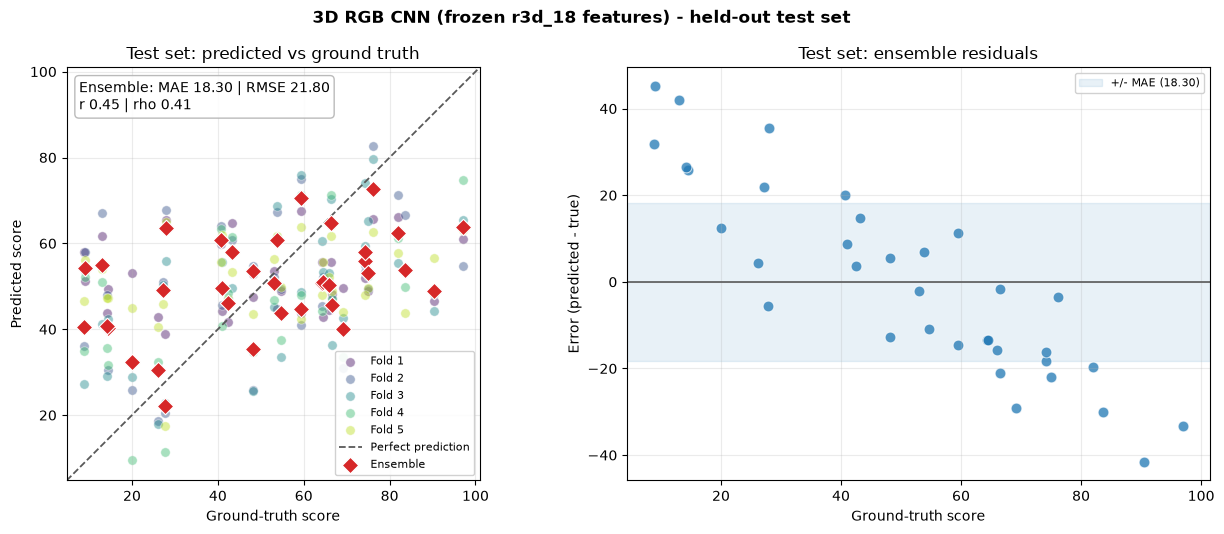

Saved plot -> C:\Users\franc\Downloads\AQA-7\AQA-7\Actions\ski_big_air\pred_vs_true_test_3dcnn.png

Test metrics per fold and ensemble:
   split    mae   rmse  pearson  spearman
  Fold 1 20.419 24.532    0.146     0.170
  Fold 2 19.602 23.908    0.342     0.307
  Fold 3 17.217 20.635    0.541     0.521
  Fold 4 18.444 21.474    0.495     0.426
  Fold 5 19.848 23.383    0.293     0.295
Ensemble 18.303 21.797    0.447     0.410


In [4]:
# --- 8. Visual diagnostics: predicted vs true test scores -----------------
# Rebuilds the test predictions from the cached features + saved fold heads,
# so this cell also works if you only rerun it (no need to rerun the CV cell).
import re
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from pathlib import Path
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

DATA_DIR = Path("C:/Users/franc/Downloads/AQA-7/AQA-7/Actions/ski_big_air")
CKPT_DIR = DATA_DIR / "checkpoints_3dcnn"
CACHE_PATH = CKPT_DIR / "r3d18_feature_cache_v1.npz"


class _PlotHead(nn.Module):
    """Rebuilds the MLP head saved by the CV cell (Dropout/Linear/ReLU blocks)."""

    def __init__(self, in_dim=512, hidden=(256, 64), dropout=0.5):
        super().__init__()
        layers = [nn.Dropout(p=dropout)]
        prev = in_dim
        for width in hidden:
            layers += [nn.Linear(prev, width), nn.ReLU(inplace=True),
                       nn.Dropout(p=dropout)]
            prev = width
        layers += [nn.Linear(prev, 1), nn.Sigmoid()]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)


def _hidden_from_state(state_dict):
    """Read the hidden widths straight out of a saved head state_dict."""
    idx = sorted(int(m.group(1)) for k in state_dict
                 if (m := re.match(r"net\.(\d+)\.weight$", k))
                 and state_dict[k].dim() == 2)
    widths = [state_dict[f"net.{i}.weight"].shape[0] for i in idx]
    return tuple(widths[:-1])          # drop the single output unit


@torch.no_grad()
def _load_and_predict(path, X):
    ckpt = torch.load(path, map_location="cpu", weights_only=True)
    sd = ckpt["state_dict"]
    head = _PlotHead(X.shape[1], hidden=_hidden_from_state(sd))
    head.load_state_dict(sd)
    head.eval()
    X = (X - ckpt["mean"].numpy()) / ckpt["std"].numpy()
    return head(torch.from_numpy(np.ascontiguousarray(X))).numpy() * 100.0


def _metrics(pred, true):
    pred = np.asarray(pred, float).ravel()
    true = np.asarray(true, float).ravel()
    return {
        "mae": float(np.mean(np.abs(pred - true))),
        "rmse": float(np.sqrt(np.mean((pred - true) ** 2))),
        "pearson": float(pearsonr(pred, true)[0]) if len(pred) > 1 else 0.0,
        "spearman": float(spearmanr(pred, true)[0]) if len(pred) > 1 else 0.0,
    }


# --- Data: held-out test clips, clean view only ---------------------------
with np.load(CACHE_PATH, allow_pickle=False) as z:
    CACHE = {str(k): v for k, v in zip(z["keys"], z["features"])}

splits = pd.read_csv(DATA_DIR / "splits.csv", dtype={"filename": str})
test_df = splits[splits["split"] == "test"].reset_index(drop=True)
test_names = test_df["filename"].astype(str)
y_true = test_df["target"].to_numpy(np.float64)
X_test = np.stack([CACHE[f"{n}|0"] for n in test_names])

head_paths = sorted(CKPT_DIR.glob("best_head_fold*.pth"),
                    key=lambda p: int(p.stem.replace("best_head_fold", "")))
assert head_paths, f"no head checkpoints found in {CKPT_DIR}"

fold_preds = np.stack([_load_and_predict(p, X_test) for p in head_paths])
y_pred = fold_preds.mean(0)
m = _metrics(y_pred, y_true)
fold_metrics = [_metrics(fold_preds[i], y_true) for i in range(len(head_paths))]

# --- Plot ----------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
colors = plt.cm.viridis(np.linspace(0.05, 0.9, len(head_paths)))

# (a) predicted vs ground truth
ax = axes[0]
for i in range(len(head_paths)):
    ax.scatter(y_true, fold_preds[i], s=46, alpha=0.45, color=colors[i],
               edgecolor="white", linewidth=0.6, label=f"Fold {i + 1}")

lo = min(y_true.min(), y_pred.min()) - 4
hi = max(y_true.max(), y_pred.max()) + 4
ax.plot([lo, hi], [lo, hi], "--", color="0.35", lw=1.3,
        label="Perfect prediction")
ax.scatter(y_true, y_pred, s=70, color="tab:red", marker="D",
           edgecolor="white", linewidth=0.8, zorder=5, label="Ensemble")
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)
ax.set_aspect("equal")
ax.set_xlabel("Ground-truth score")
ax.set_ylabel("Predicted score")
ax.set_title("Test set: predicted vs ground truth")
ax.grid(alpha=0.25)
ax.text(0.03, 0.97,
        f"Ensemble: MAE {m['mae']:.2f} | RMSE {m['rmse']:.2f}\n"
        f"r {m['pearson']:.2f} | rho {m['spearman']:.2f}",
        transform=ax.transAxes, va="top", fontsize=10,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.9,
                  edgecolor="0.7"))
ax.legend(loc="lower right", fontsize=8, framealpha=0.9)

# (b) residuals of the ensemble
ax = axes[1]
resid = y_pred - y_true
ax.axhline(0, color="0.35", lw=1.2)
ax.axhspan(-m["mae"], m["mae"], color="tab:blue", alpha=0.10,
           label=f"+/- MAE ({m['mae']:.2f})")
ax.scatter(y_true, resid, s=60, color="tab:blue", alpha=0.75,
           edgecolor="white", linewidth=0.7)
ax.set_xlabel("Ground-truth score")
ax.set_ylabel("Error (predicted - true)")
ax.set_title("Test set: ensemble residuals")
ax.grid(alpha=0.25)
ax.legend(loc="upper right", fontsize=8, framealpha=0.9)

fig.suptitle("3D RGB CNN (frozen r3d_18 features) - held-out test set",
             fontweight="bold")
fig.tight_layout()
out_path = DATA_DIR / "pred_vs_true_test_3dcnn.png"
fig.savefig(out_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved plot -> {out_path}")

summary = pd.DataFrame({
    "split": [f"Fold {i + 1}" for i in range(len(head_paths))] + ["Ensemble"],
    **{k: [fm[k] for fm in fold_metrics] + [m[k]]
       for k in ("mae", "rmse", "pearson", "spearman")},
})
print("\nTest metrics per fold and ensemble:")
print(summary.round(3).to_string(index=False))

In [7]:
# --- 8A. Fall classifier (standalone) --------------------------------------
# labels_CV.csv now contains an explicit annotation:
#     fall = 1  -> the jump ended in a fall
#     fall = 0  -> clean landing
# This model predicts `fall` directly from the frozen r3d18 features.
# It is trained/evaluated on its own; its output is NOT passed to the score
# regressor (cell 8C), so the two tasks stay independent.

import multiprocessing
from pathlib import Path
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from scipy.stats import rankdata

N_CPU = multiprocessing.cpu_count()
torch.set_num_threads(max(1, N_CPU - 2))
try:
    torch.set_num_interop_threads(1)
except RuntimeError:
    pass

SEED = 42
K_FOLDS = 5
AUG_VIEWS = 0
EVAL_VIEWS = (0,)
TRAIN_VIEWS = (0,)

# Fall-classifier hyper-parameters
FALL_LR = 1e-3
FALL_EPOCHS = 100
FALL_PATIENCE = 20
HEAD_BATCH = 64
HEAD_WD = 1e-3
DROP_OUT = 0.5
FALL_DECISION_THRESHOLD = 0.5   # fixed default; tuned thresholds are also reported

torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cpu")
print(f"Using device: {device} | CPU threads: {torch.get_num_threads()}")

# --- 1. Labels, splits and folds ------------------------------------------
DATA_DIR = Path("C:/Users/franc/Downloads/AQA-7/AQA-7/Actions/ski_big_air") if "DATA_DIR" not in globals() else DATA_DIR
CKPT_DIR = DATA_DIR / "checkpoints_3dcnn"
SPLITS_CSV = DATA_DIR / "splits.csv" 
labels_df = pd.read_csv(DATA_DIR / "labels_CV.csv", dtype={"filename": str})

if "fall" not in labels_df.columns:
    raise KeyError(
        "labels_CV.csv has no `fall` column. Add it (1 = fall, 0 = no fall) "
        "or use the score-derived fall target instead."
    )

# Keep only valid binary annotations; report anything that is dropped.
valid_fall = labels_df["fall"].isin([0, 1])
if (~valid_fall).any():
    bad = labels_df.loc[~valid_fall, ["filename", "target", "fall"]]
    print(f"[WARN] {len(bad)} row(s) with an invalid `fall` label are excluded:")
    print(bad.to_string(index=False))
labels_df = labels_df.loc[valid_fall].copy()
labels_df["fall"] = labels_df["fall"].astype(int)

print(f"fall labels: {int((labels_df['fall'] == 1).sum())} fall / "
      f"{int((labels_df['fall'] == 0).sum())} no-fall "
      f"({labels_df['fall'].mean():.1%} positive)")


# Keep the split definition in sync with cell 3 (70/10/20). splits.csv is the
# random clip split; the leak-free frame is splits_grouped.csv.
SPLIT_FRACTIONS = (0.70, 0.10, 0.20)


def make_splits(df, out_csv, seed=SEED, n_bins=5, fractions=SPLIT_FRACTIONS):
    """Deterministic, target-stratified train/val/test split (keeps `fall`)."""
    df = df.copy()
    df["_bin"] = pd.qcut(df["target"].rank(method="first"), n_bins, labels=False)
    rng = np.random.default_rng(seed)
    split = pd.Series(index=df.index, dtype=object)
    for _, idx in df.groupby("_bin").groups.items():
        idx = np.array(list(idx), dtype=int)
        rng.shuffle(idx)
        n_tr = int(round(fractions[0] * len(idx)))
        n_va = max(1, int(round(fractions[1] * len(idx)))) if len(idx) >= 3 else 0
        split.loc[idx[:n_tr]] = "train"
        split.loc[idx[n_tr:n_tr + n_va]] = "val"
        split.loc[idx[n_tr + n_va:]] = "test"
    df["split"] = split
    df[["filename", "target", "fall", "split"]].to_csv(out_csv, index=False)
    return df[["filename", "target", "fall", "split"]]


if SPLITS_CSV.exists():
    splits = pd.read_csv(SPLITS_CSV, dtype={"filename": str})
    test_frac = float((splits["split"] == "test").mean())
    if abs(test_frac - SPLIT_FRACTIONS[2]) > 0.02:
        # Warn only - a modelling cell must not rewrite a shared split file.
        print(f"[WARN] splits.csv is {test_frac:.1%} test, expected "
              f"{SPLIT_FRACTIONS[2]:.0%}; keeping the existing file.")
else:
    splits = make_splits(labels_df, SPLITS_CSV, fractions=SPLIT_FRACTIONS)

# splits.csv may predate the `fall` column, so always re-attach the labels
# from labels_CV.csv (the single source of truth).
splits = splits[["filename", "split"]].merge(
    labels_df[["filename", "target", "fall"]], on="filename", how="inner"
)
uncovered = sorted(set(labels_df["filename"]) - set(splits["filename"]))
if uncovered:
    print(f"[WARN] {len(uncovered)} label(s) missing from splits.csv: {uncovered[:5]}")

train_val_df = splits[splits["split"] != "test"].reset_index(drop=True)
test_df = splits[splits["split"] == "test"].reset_index(drop=True)
assert not (set(train_val_df["filename"]) & set(test_df["filename"])), \
    "a filename appears in both train/val and test in splits.csv"
print(f"Train+val clips: {len(train_val_df)} | hold-out test clips: {len(test_df)}")


def stratified_fold_ids(targets, n_splits, seed=SEED):
    bins = pd.qcut(pd.Series(targets).rank(method="first"), n_splits, labels=False).to_numpy()
    fold_ids = np.empty(len(targets), dtype=int)
    rng = np.random.default_rng(seed)
    for b in range(n_splits):
        idx = np.flatnonzero(bins == b)
        rng.shuffle(idx)
        fold_ids[idx] = np.arange(len(idx)) % n_splits
    return fold_ids


K_FOLDS = max(2, min(K_FOLDS, len(train_val_df) // 5))
fold_ids = stratified_fold_ids(train_val_df["target"], K_FOLDS)
fold_splits = []
for fold in range(K_FOLDS):
    tr_idx = np.flatnonzero(fold_ids != fold)
    va_idx = np.flatnonzero(fold_ids == fold)
    fold_splits.append((tr_idx, va_idx))

print("fall rate per fold: " + " | ".join(
    f"f{f}: {train_val_df['fall'].iloc[va].mean():.0%}" for f, (_, va) in enumerate(fold_splits)
))

# --- 2. Frozen-backbone feature cache -------------------------------------
CKPT_DIR = DATA_DIR / "checkpoints_3dcnn"
CACHE_PATH = CKPT_DIR / "r3d18_feature_cache_v1.npz"

with np.load(CACHE_PATH, allow_pickle=False) as z:
    CACHE = {str(k): v for k, v in zip(z["keys"], z["features"])}

# Adapt TRAIN_VIEWS to whatever views exist in the cache (default: (0,) for full video frames)
_avail_views = sorted({int(k.split("|")[1]) for k in CACHE.keys() if "|" in k})
TRAIN_VIEWS = tuple(_avail_views) if _avail_views else (0,)
EVAL_VIEWS = (0,)


def feature_bundle(names, views):
    return np.stack([CACHE[f"{n}|{v}"] for n in names for v in views])


def fall_bundle(names, fall, views):
    X = feature_bundle(names, views)
    y = np.repeat(np.asarray(fall, dtype=int), len(views))
    return X, y


def fit_scaler(X):
    return (X.mean(0, keepdims=True).astype(np.float32),
            (X.std(0, keepdims=True) + 1e-6).astype(np.float32))


def apply_scaler(X, scaler):
    return (X - scaler[0]) / scaler[1]


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.asarray(z, dtype=np.float64)))


def roc_auc(y_true, y_prob):
    """Rank-based ROC AUC (tie-aware); nan if only one class is present."""
    y_true = np.asarray(y_true, dtype=int).ravel()
    y_prob = np.asarray(y_prob, dtype=float).ravel()
    n_pos = int(y_true.sum())
    n_neg = len(y_true) - n_pos
    if n_pos == 0 or n_neg == 0:
        return float("nan")
    ranks = rankdata(y_prob)
    return float((ranks[y_true == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def classification_metrics(y_true, y_prob, threshold=FALL_DECISION_THRESHOLD):
    y_true = np.asarray(y_true, dtype=int).ravel()
    y_prob = np.asarray(y_prob, dtype=float).ravel()
    pred = (y_prob >= threshold).astype(int)
    tp = int(((pred == 1) & (y_true == 1)).sum())
    fp = int(((pred == 1) & (y_true == 0)).sum())
    fn = int(((pred == 0) & (y_true == 1)).sum())
    tn = int(((pred == 0) & (y_true == 0)).sum())
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return {
        "accuracy": float((tp + tn) / max(1, len(y_true))),
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "auc": roc_auc(y_true, y_prob),
        "tn": tn, "fp": fp, "fn": fn, "tp": tp,
    }


def best_f1_threshold(y_true, y_prob):
    """Pick the threshold that maximises F1 on the validation fold."""
    grid = np.unique(np.clip(np.asarray(y_prob, dtype=float), 0.0, 1.0))
    best_t, best_f1 = 0.5, -1.0
    for t in grid:
        f1 = classification_metrics(y_true, y_prob, float(t))["f1"]
        if f1 > best_f1:
            best_t, best_f1 = float(t), f1
    return best_t


# --- 3. Fall classifier ----------------------------------------------------
class FallClassifier(nn.Module):
    """Binary fall classifier on top of the frozen r3d18 512-D features."""

    def __init__(self, in_dim=512, dropout=DROP_OUT):
        super().__init__()
        self.net = nn.Sequential(
            nn.Dropout(p=dropout),
            nn.Linear(in_dim, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, 1),   # linear output -> BCEWithLogitsLoss
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)


def train_fall_classifier(Xtr, ytr, Xva, yva, seed=SEED):
    torch.manual_seed(seed)
    scaler = fit_scaler(Xtr)
    Xtr_s = apply_scaler(Xtr, scaler)
    Xva_s = apply_scaler(Xva, scaler)

    model = FallClassifier(Xtr.shape[1]).to(device)
    n_pos = max(1, int(ytr.sum()))
    n_neg = int(len(ytr) - ytr.sum())
    pos_weight = torch.tensor([n_neg / n_pos], dtype=torch.float32)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    val_criterion = nn.BCEWithLogitsLoss()      # unweighted -> stable early stopping
    optimizer = torch.optim.AdamW(model.parameters(), lr=FALL_LR, weight_decay=HEAD_WD)

    Xtr_t = torch.from_numpy(Xtr_s).to(device)
    ytr_t = torch.from_numpy(ytr.astype(np.float32)).to(device)
    Xva_t = torch.from_numpy(Xva_s).to(device)
    yva_t = torch.from_numpy(yva.astype(np.float32)).to(device)

    best_loss, best_state, bad = float("inf"), None, 0
    n = len(Xtr_t)

    for epoch in range(1, FALL_EPOCHS + 1):
        model.train()
        perm = torch.randperm(n)
        for i in range(0, n, HEAD_BATCH):
            idx = perm[i:i + HEAD_BATCH]
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(Xtr_t[idx]), ytr_t[idx])
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            val_loss = val_criterion(model(Xva_t), yva_t).item()

        if val_loss < best_loss - 1e-4:
            best_loss, bad = val_loss, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= FALL_PATIENCE:
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    model.eval()
    return model, scaler


def predict_fall_prob(model, X, scaler):
    model.eval()
    X_s = apply_scaler(X, scaler)
    with torch.no_grad():
        logits = model(torch.from_numpy(np.ascontiguousarray(X_s))).cpu().numpy()
    return sigmoid(logits)


# --- 4. Cross-validated fall classification --------------------------------
test_names = test_df["filename"].astype(str).tolist()
Xte_fall = feature_bundle(test_names, EVAL_VIEWS)
yte_fall = test_df["fall"].to_numpy(dtype=int)

fall_results = []
fold_fall_val_prob, fold_fall_val_true = [], []
fold_fall_test_prob, fold_fall_thresholds = [], []

t_fall = time.time()
for fold, (tr_idx, va_idx) in enumerate(fold_splits):
    print(f"\n{'=' * 45}\n FALL CLASSIFIER - FOLD {fold + 1}/{K_FOLDS}\n{'=' * 45}")
    t0 = time.time()

    tr = train_val_df.iloc[tr_idx]
    va = train_val_df.iloc[va_idx]

    Xtr, ytr = fall_bundle(tr["filename"].astype(str), tr["fall"], TRAIN_VIEWS)
    Xva, yva = fall_bundle(va["filename"].astype(str), va["fall"], EVAL_VIEWS)

    model, scaler = train_fall_classifier(Xtr, ytr, Xva, yva, seed=SEED + fold)
    p_va = predict_fall_prob(model, Xva, scaler)
    p_te = predict_fall_prob(model, Xte_fall, scaler)

    thr = best_f1_threshold(yva, p_va)
    m = classification_metrics(yva, p_va, FALL_DECISION_THRESHOLD)
    m_t = classification_metrics(yva, p_va, thr)

    fold_fall_val_prob.append(p_va)
    fold_fall_val_true.append(yva)
    fold_fall_test_prob.append(p_te)
    fold_fall_thresholds.append(thr)

    fall_results.append({
        "fold": fold + 1,
        "val_accuracy": m["accuracy"],
        "val_precision": m["precision"],
        "val_recall": m["recall"],
        "val_f1": m["f1"],
        "val_auc": m["auc"],
        "val_f1_tuned": m_t["f1"],
        "threshold_tuned": thr,
    })

    torch.save(
        {
            "state_dict": model.state_dict(),
            "scaler_mean": scaler[0],
            "scaler_std": scaler[1],
            "threshold": thr,
            "seed": SEED + fold,
        },
        CKPT_DIR / f"fall_clf_fold{fold}.pth",
    )

    print(f"  val: acc {m['accuracy']:.3f} | prec {m['precision']:.3f} | "
          f"rec {m['recall']:.3f} | F1 {m['f1']:.3f} | AUC {m['auc']:.3f} | "
          f"F1@{thr:.2f} {m_t['f1']:.3f} | {time.time() - t0:.1f}s")

print(f"\nFall classifier trained in {time.time() - t_fall:.1f}s")
print(pd.DataFrame(fall_results).round(3).to_string(index=False))

fall_ensemble_test_prob = np.mean(fold_fall_test_prob, axis=0)
fall_test_threshold = float(np.mean(fold_fall_thresholds))
fall_test_metrics = classification_metrics(yte_fall, fall_ensemble_test_prob, fall_test_threshold)

print(f"\nHeld-out test set ({len(yte_fall)} clips, {int(yte_fall.sum())} falls), "
      f"threshold {fall_test_threshold:.2f}")
print(f"  accuracy {fall_test_metrics['accuracy']:.3f} | "
      f"precision {fall_test_metrics['precision']:.3f} | "
      f"recall {fall_test_metrics['recall']:.3f} | "
      f"F1 {fall_test_metrics['f1']:.3f} | AUC {fall_test_metrics['auc']:.3f}")
print(f"  confusion: TN {fall_test_metrics['tn']} FP {fall_test_metrics['fp']} "
      f"FN {fall_test_metrics['fn']} TP {fall_test_metrics['tp']}")

# The tuned threshold is noisy with so few test falls -> also report the fixed 0.5 cut.
fall_test_metrics_05 = classification_metrics(yte_fall, fall_ensemble_test_prob, 0.5)
print(f"  fixed 0.5 threshold: precision {fall_test_metrics_05['precision']:.3f} | "
      f"recall {fall_test_metrics_05['recall']:.3f} | F1 {fall_test_metrics_05['f1']:.3f} | "
      f"confusion TN {fall_test_metrics_05['tn']} FP {fall_test_metrics_05['fp']} "
      f"FN {fall_test_metrics_05['fn']} TP {fall_test_metrics_05['tp']}")

np.savez(
    CKPT_DIR / "fall_clf_predictions.npz",
    test_names=np.asarray(test_names),
    test_fall=yte_fall,
    test_prob=fall_ensemble_test_prob,
    fold_test_prob=np.stack(fold_fall_test_prob),
    fold_thresholds=np.asarray(fold_fall_thresholds),
    # Pooled out-of-fold validation probabilities (for calibration + gating)
    val_prob=np.concatenate(fold_fall_val_prob),
    val_true=np.concatenate(fold_fall_val_true),
    val_fold=np.concatenate([np.full(len(p), f, dtype=int)
                             for f, p in enumerate(fold_fall_val_prob)]),
)
print(f"Saved fall checkpoints and predictions -> {CKPT_DIR}")

Using device: cpu | CPU threads: 16
fall labels: 32 fall / 202 no-fall (13.7% positive)
Train+val clips: 189 | hold-out test clips: 45
fall rate per fold: f0: 15% | f1: 15% | f2: 13% | f3: 14% | f4: 11%

 FALL CLASSIFIER - FOLD 1/5
  val: acc 0.950 | prec 1.000 | rec 0.667 | F1 0.800 | AUC 0.922 | F1@0.45 0.833 | 0.7s

 FALL CLASSIFIER - FOLD 2/5
  val: acc 0.875 | prec 0.600 | rec 0.500 | F1 0.545 | AUC 0.745 | F1@0.76 0.600 | 0.5s

 FALL CLASSIFIER - FOLD 3/5
  val: acc 0.872 | prec 0.500 | rec 0.400 | F1 0.444 | AUC 0.712 | F1@0.42 0.600 | 0.5s

 FALL CLASSIFIER - FOLD 4/5
  val: acc 0.829 | prec 0.400 | rec 0.400 | F1 0.400 | AUC 0.680 | F1@0.38 0.462 | 0.4s

 FALL CLASSIFIER - FOLD 5/5
  val: acc 0.829 | prec 0.333 | rec 0.500 | F1 0.400 | AUC 0.677 | F1@0.82 0.571 | 0.5s

Fall classifier trained in 2.6s
 fold  val_accuracy  val_precision  val_recall  val_f1  val_auc  val_f1_tuned  threshold_tuned
    1         0.950          1.000       0.667   0.800    0.922         0.833       

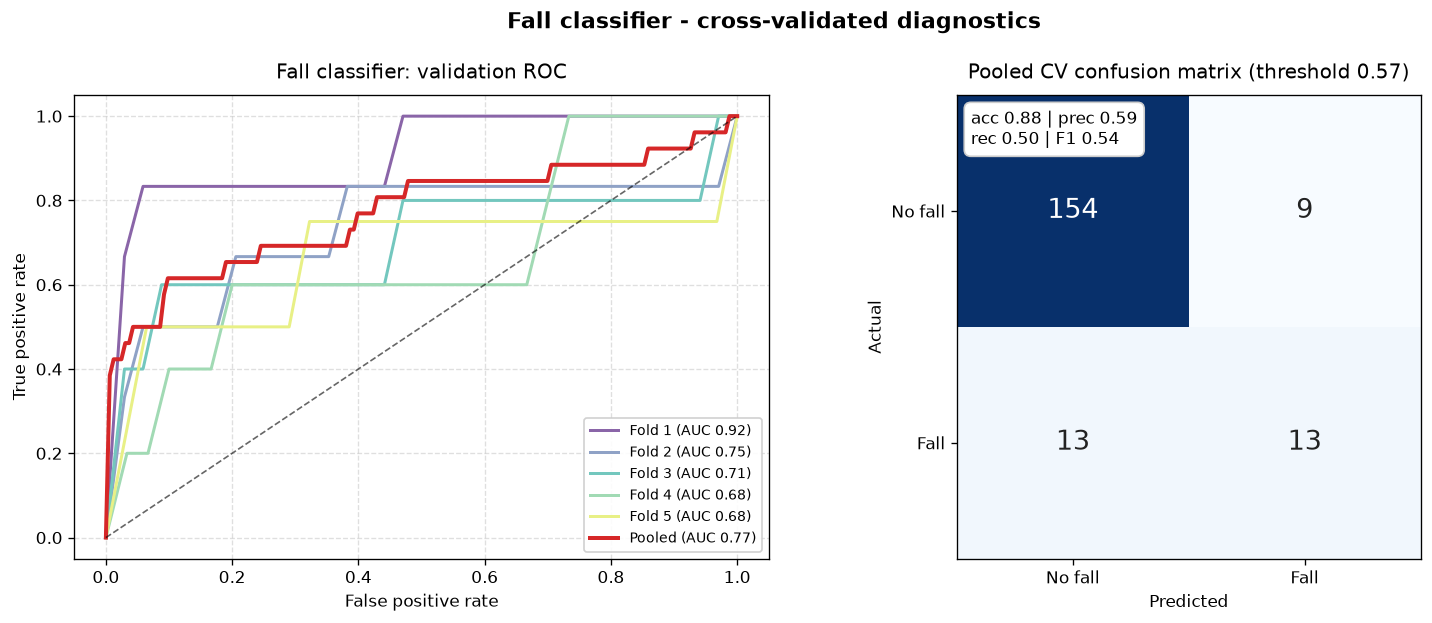

Pooled CV @ threshold 0.57: acc 0.884 | precision 0.591 | recall 0.500 | F1 0.542 | AUC 0.774


In [8]:
# --- 8B. Fall classifier diagnostics ---------------------------------------
# ROC curves per validation fold + pooled confusion matrix at the tuned threshold.

import numpy as np
import matplotlib.pyplot as plt


def roc_curve_points(y_true, y_prob):
    """Return FPR/TPR points (including the origin) for a ROC curve."""
    y_true = np.asarray(y_true, dtype=int).ravel()
    y_prob = np.asarray(y_prob, dtype=float).ravel()
    order = np.argsort(-y_prob, kind="mergesort")
    y_true = y_true[order]
    tps = np.cumsum(y_true)
    fps = np.cumsum(1 - y_true)
    tpr = np.concatenate([[0.0], tps / max(1, tps[-1])])
    fpr = np.concatenate([[0.0], fps / max(1, fps[-1])])
    keep = np.concatenate([[True], np.diff(fpr) > 0])
    return fpr[keep], tpr[keep]


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), dpi=120)
colors = ["#8a65a8", "#8fa2c6", "#73c7be", "#a1dab4", "#e8f086"]

for fold, (p, y) in enumerate(zip(fold_fall_val_prob, fold_fall_val_true)):
    fpr, tpr = roc_curve_points(y, p)
    auc = roc_auc(y, p)
    ax1.plot(fpr, tpr, color=colors[fold % len(colors)], linewidth=1.8,
             label=f"Fold {fold + 1} (AUC {auc:.2f})")

pooled_true = np.concatenate(fold_fall_val_true)
pooled_prob = np.concatenate(fold_fall_val_prob)
fpr, tpr = roc_curve_points(pooled_true, pooled_prob)
ax1.plot(fpr, tpr, color="#d62728", linewidth=2.4,
         label=f"Pooled (AUC {roc_auc(pooled_true, pooled_prob):.2f})")
ax1.plot([0, 1], [0, 1], "k--", linewidth=1.0, alpha=0.6)
ax1.set_xlabel("False positive rate")
ax1.set_ylabel("True positive rate")
ax1.set_title("Fall classifier: validation ROC", fontsize=12, pad=10)
ax1.grid(True, linestyle="--", alpha=0.4)
ax1.legend(loc="lower right", fontsize=8.5, framealpha=0.9)

thr = float(np.mean(fold_fall_thresholds))
m = classification_metrics(pooled_true, pooled_prob, thr)
conf = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
ax2.imshow(conf, cmap="Blues", interpolation="nearest")
for i in range(2):
    for j in range(2):
        ax2.text(j, i, int(conf[i, j]), ha="center", va="center", fontsize=16,
                 color="white" if conf[i, j] > conf.max() / 2 else "#222222")
ax2.set_xticks([0, 1], ["No fall", "Fall"])
ax2.set_yticks([0, 1], ["No fall", "Fall"])
ax2.set_xlabel("Predicted")
ax2.set_ylabel("Actual")
ax2.set_title(f"Pooled CV confusion matrix (threshold {thr:.2f})", fontsize=12, pad=10)
ax2.text(0.03, 0.97,
         f"acc {m['accuracy']:.2f} | prec {m['precision']:.2f}\n"
         f"rec {m['recall']:.2f} | F1 {m['f1']:.2f}",
         transform=ax2.transAxes, va="top", fontsize=10,
         bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#cccccc"))

plt.suptitle("Fall classifier - cross-validated diagnostics", fontsize=13, fontweight="bold", y=0.99)
plt.tight_layout()
plt.show()

print(f"Pooled CV @ threshold {thr:.2f}: acc {m['accuracy']:.3f} | "
      f"precision {m['precision']:.3f} | recall {m['recall']:.3f} | F1 {m['f1']:.3f} | "
      f"AUC {roc_auc(pooled_true, pooled_prob):.3f}")


In [9]:
# --- 8C. Score regressor (standalone) --------------------------------------
# Predicts the continuous score from frozen r3d18 features. With
# USE_END_OF_CLIP it concatenates the full-clip descriptor with the last-8
# and last-4 frame descriptors, which is where a fall/crash actually happens.
# The fall classifier from 8A is still NOT used as an input here.

import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from scipy.stats import pearsonr, spearmanr

DATA_DIR = Path("C:/Users/franc/Downloads/AQA-7/AQA-7/Actions/ski_big_air") if "DATA_DIR" not in globals() else DATA_DIR
CKPT_DIR = DATA_DIR / "checkpoints_3dcnn"
EVAL_VIEWS = (0,)
TRAIN_VIEWS = (0,)

REG_LR = 6e-3
REG_EPOCHS = 150
REG_PATIENCE = 30
TARGET_SCALE = 100.0

# Feature set: full clip + end-of-clip windows (from the window cache).
USE_END_OF_CLIP = True
END_WINDOWS = ("last8", "last4")


def regression_metrics(preds, targets):
    preds = np.asarray(preds, float).ravel()
    targets = np.asarray(targets, float).ravel()
    pearson = pearsonr(preds, targets)[0] if len(preds) > 1 and np.std(preds) > 1e-12 else 0.0
    spearman = spearmanr(preds, targets)[0] if len(preds) > 1 and np.std(preds) > 1e-12 else 0.0
    return {
        "mae": float(np.mean(np.abs(preds - targets))),
        "rmse": float(np.sqrt(np.mean((preds - targets) ** 2))),
        "pearson": float(pearson),
        "spearman": float(spearman),
    }


CKPT_DIR = DATA_DIR / "checkpoints_3dcnn"
WINDOW_CACHE = CKPT_DIR / "r3d18_window_cache_v1.npz"

WIN = {}
if USE_END_OF_CLIP:
    if not WINDOW_CACHE.exists():
        raise FileNotFoundError(
            f"Missing {WINDOW_CACHE}. Run the end-of-clip cell (13) once to build it."
        )
    with np.load(WINDOW_CACHE, allow_pickle=False) as z:
        WIN = {str(k): v for k, v in zip(z["keys"], z["features"])}
    needed = {f"{n}|{w}" for n in
              pd.concat([train_val_df, test_df])["filename"].astype(str)
              for w in END_WINDOWS}
    missing = needed - set(WIN)
    assert not missing, (
        f"Window cache is missing {len(missing)} entr(ies) "
        f"(e.g. {sorted(missing)[:3]}); delete {WINDOW_CACHE} and rerun cell 13."
    )


def score_bundle(names, targets, views):
    rows = []
    for name in names:
        for view in views:
            parts = [CACHE[f"{name}|{view}"]]
            if USE_END_OF_CLIP:
                parts += [WIN[f"{name}|{w}"] for w in END_WINDOWS]
            rows.append(np.concatenate(parts))
    X = np.stack(rows).astype(np.float32)
    y = np.repeat(np.asarray(targets, dtype=np.float32), len(views))
    return X, y


class ScoreRegressor(nn.Module):
    """Continuous score head on the concatenated frozen r3d18 features."""

    def __init__(self, in_dim=512, dropout=DROP_OUT):
        super().__init__()
        self.net = nn.Sequential(
            nn.Dropout(p=dropout),
            nn.Linear(in_dim, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, 1),
            nn.Sigmoid(),   # targets are scaled to [0, 1]
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)


def train_score_regressor(Xtr, ytr, Xva, yva, seed=SEED):
    torch.manual_seed(seed)
    model = ScoreRegressor(Xtr.shape[1]).to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=REG_LR, weight_decay=HEAD_WD)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=10)

    Xtr_t = torch.from_numpy(Xtr).to(device)
    ytr_t = torch.from_numpy(ytr / TARGET_SCALE).float().to(device)
    Xva_t = torch.from_numpy(Xva).to(device)
    yva_np = np.asarray(yva, dtype=np.float64)

    best_mae, best_state, best_epoch, bad = float("inf"), None, 0, 0
    n = len(Xtr_t)

    for epoch in range(1, REG_EPOCHS + 1):
        model.train()
        perm = torch.randperm(n)
        for i in range(0, n, HEAD_BATCH):
            idx = perm[i:i + HEAD_BATCH]
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(Xtr_t[idx]), ytr_t[idx])
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            val_preds = model(Xva_t).cpu().numpy() * TARGET_SCALE
        mae = float(np.mean(np.abs(val_preds - yva_np)))
        scheduler.step(mae)

        if mae < best_mae - 1e-4:
            best_mae, best_epoch, bad = mae, epoch, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= REG_PATIENCE:
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    model.eval()
    return model, {"best_epoch": best_epoch, "best_val_mae": best_mae}


def predict_score(model, X):
    model.eval()
    with torch.no_grad():
        return model(torch.from_numpy(np.ascontiguousarray(X))).cpu().numpy() * TARGET_SCALE


# --- 1. Cross-validated score regression -----------------------------------
test_names = test_df["filename"].astype(str).tolist()
Xte, yte_score = score_bundle(test_names, test_df["target"].to_numpy(), EVAL_VIEWS)
print(f"Score features: {Xte.shape[1]}-D "
      f"({('full + ' + ' + '.join(END_WINDOWS)) if USE_END_OF_CLIP else 'full clip'}) "
      f"| train+val {len(train_val_df)} | test {len(test_df)}")

fold_results, fold_test_preds = [], []
fold_val_preds, fold_val_targets = [], []
t_reg = time.time()
for fold, (tr_idx, va_idx) in enumerate(fold_splits):
    print(f"\n{'=' * 45}\n SCORE REGRESSOR - FOLD {fold + 1}/{K_FOLDS}\n{'=' * 45}")
    t0 = time.time()

    tr = train_val_df.iloc[tr_idx]
    va = train_val_df.iloc[va_idx]

    Xtr, ytr_score = score_bundle(tr["filename"].astype(str), tr["target"].to_numpy(), TRAIN_VIEWS)
    Xva, yva_score = score_bundle(va["filename"].astype(str), va["target"].to_numpy(), EVAL_VIEWS)

    scaler = fit_scaler(Xtr)
    Xtr_s = apply_scaler(Xtr, scaler)
    Xva_s = apply_scaler(Xva, scaler)
    Xte_s = apply_scaler(Xte, scaler)

    model, info = train_score_regressor(Xtr_s, ytr_score, Xva_s, yva_score, seed=SEED + fold)

    val_preds = predict_score(model, Xva_s)
    m = regression_metrics(val_preds, yva_score)
    fold_val_preds.append(val_preds)
    fold_val_targets.append(yva_score)

    fold_test_preds.append(predict_score(model, Xte_s))
    fold_results.append({
        "fold": fold + 1,
        "val_mae": m["mae"],
        "val_rmse": m["rmse"],
        "val_pearson": m["pearson"],
        "val_spearman": m["spearman"],
        "best_epoch": info["best_epoch"],
    })

    torch.save(
        {
            "state_dict": model.state_dict(),
            "scaler_mean": scaler[0],
            "scaler_std": scaler[1],
            "seed": SEED + fold,
            "best_epoch": info["best_epoch"],
        },
        CKPT_DIR / f"score_reg_fold{fold}.pth",
    )

    print(f"  val MAE {m['mae']:5.2f} | RMSE {m['rmse']:5.2f} | "
          f"r {m['pearson']:.3f} | rho {m['spearman']:.3f} | "
          f"best epoch {info['best_epoch']} | {time.time() - t0:4.1f}s")

print(f"\nScore regressor trained in {time.time() - t_reg:.1f}s")
print(pd.DataFrame(fold_results).round(3).to_string(index=False))

# --- 2. Final evaluation on the held-out test set --------------------------
ensemble_test_preds = np.mean(fold_test_preds, axis=0)
ensemble = regression_metrics(ensemble_test_preds, yte_score)

print(f"\n{'=' * 45}\n SCORE REGRESSOR - HELD-OUT TEST \n{'=' * 45}")
print(f"Ensemble ({K_FOLDS}-fold averaged) | MAE {ensemble['mae']:.2f} | "
      f"RMSE {ensemble['rmse']:.2f} | r {ensemble['pearson']:.3f} | rho {ensemble['spearman']:.3f}")

np.savez(
    CKPT_DIR / "score_reg_predictions.npz",
    test_names=np.asarray(test_names),
    test_target=yte_score.astype(np.float32),
    test_pred=ensemble_test_preds.astype(np.float32),
    fold_test_pred=np.stack(fold_test_preds).astype(np.float32),
    # Out-of-fold validation predictions (for calibrating/choosing the gate)
    val_pred=np.concatenate(fold_val_preds).astype(np.float32),
    val_target=np.concatenate(fold_val_targets).astype(np.float32),
)

Score features: 1536-D (full + last8 + last4) | train+val 189 | test 45

 SCORE REGRESSOR - FOLD 1/5
  val MAE 16.57 | RMSE 19.68 | r 0.703 | rho 0.666 | best epoch 16 |  1.5s

 SCORE REGRESSOR - FOLD 2/5
  val MAE 15.91 | RMSE 19.81 | r 0.671 | rho 0.719 | best epoch 29 |  2.3s

 SCORE REGRESSOR - FOLD 3/5
  val MAE 17.01 | RMSE 22.90 | r 0.487 | rho 0.444 | best epoch 10 |  1.2s

 SCORE REGRESSOR - FOLD 4/5
  val MAE 15.48 | RMSE 21.22 | r 0.529 | rho 0.422 | best epoch 9 |  1.3s

 SCORE REGRESSOR - FOLD 5/5
  val MAE 17.42 | RMSE 22.17 | r 0.507 | rho 0.484 | best epoch 5 |  1.3s

Score regressor trained in 7.7s
 fold  val_mae  val_rmse  val_pearson  val_spearman  best_epoch
    1   16.565    19.681        0.703         0.666          16
    2   15.910    19.813        0.671         0.719          29
    3   17.009    22.904        0.487         0.444          10
    4   15.481    21.225        0.529         0.422           9
    5   17.416    22.170        0.507         0.484      

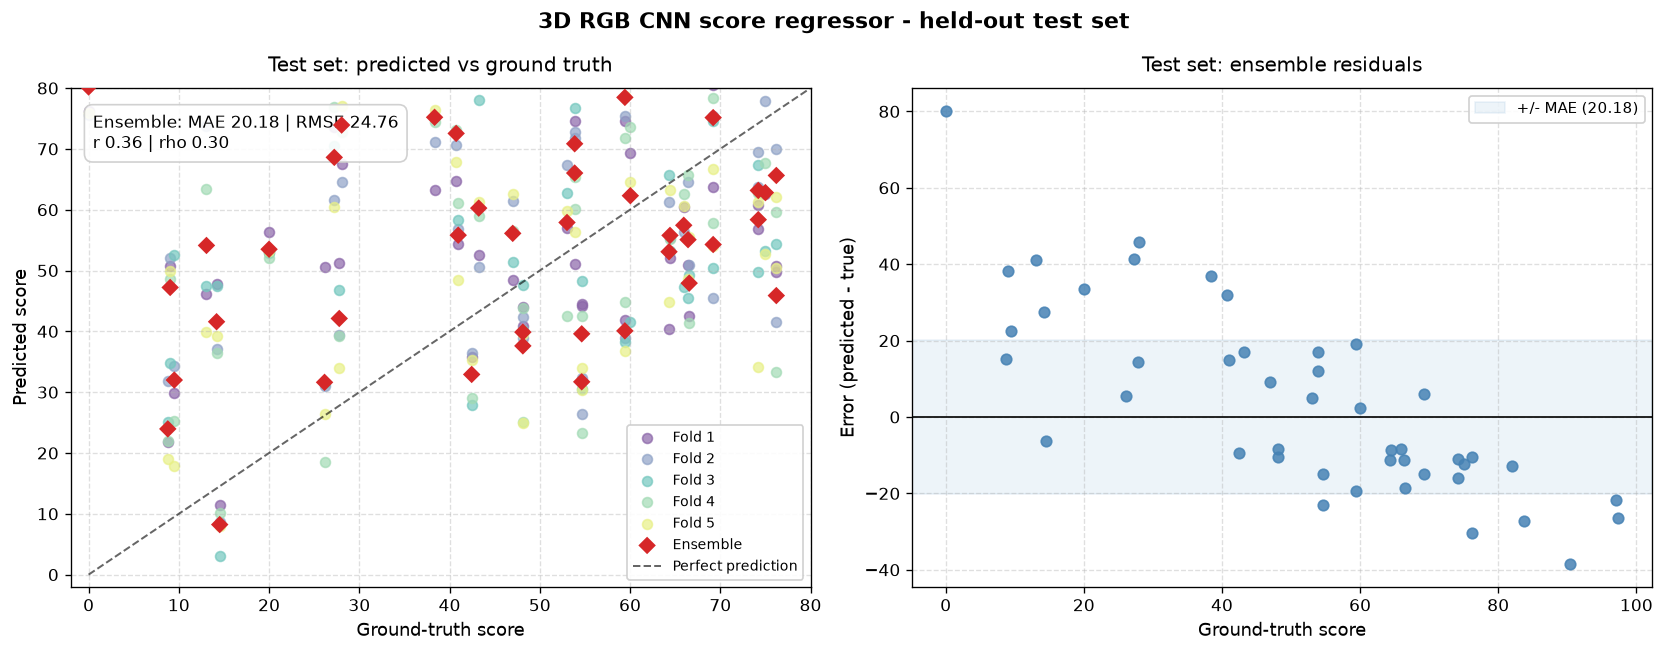

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# --- 8D. Score regressor diagnostics --------------------------------------
# 2-panel diagnostic plot for the standalone score regressor trained in cell 8C.
# (Fall-classifier diagnostics are in cell 8B.)

ensemble_preds = np.mean(fold_test_preds, axis=0)
residuals = ensemble_preds - yte_score

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=120)

# Fold color palette matching the original visualization
fold_colors = ["#8a65a8", "#8fa2c6", "#73c7be", "#a1dab4", "#e8f086"]

# --- Left Plot: Predicted vs Ground Truth ---
for fold, preds in enumerate(fold_test_preds):
    ax1.scatter(
        yte_score,
        preds,
        color=fold_colors[fold % len(fold_colors)],
        alpha=0.7,
        s=35,
        label=f"Fold {fold + 1}",
    )

# Ensemble predictions (Red Diamonds)
ax1.scatter(
    yte_score,
    ensemble_preds,
    color="#d62728",
    marker="D",
    s=55,
    edgecolor="none",
    zorder=5,
    label="Ensemble",
)

# Reference line for perfect prediction (y = x)
ax1.plot([0, 80], [0, 80], "k--", alpha=0.6, linewidth=1.2, label="Perfect prediction")

# Performance metrics box
metrics_text = (
    f"Ensemble: MAE {ensemble['mae']:.2f} | RMSE {ensemble['rmse']:.2f}\n"
    f"r {ensemble['pearson']:.2f} | rho {ensemble['spearman']:.2f}"
)
ax1.text(
    0.03,
    0.95,
    metrics_text,
    transform=ax1.transAxes,
    verticalalignment="top",
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="#cccccc", alpha=0.9),
)

ax1.set_title("Test set: predicted vs ground truth", fontsize=12, pad=10)
ax1.set_xlabel("Ground-truth score", fontsize=10.5)
ax1.set_ylabel("Predicted score", fontsize=10.5)
ax1.set_xlim(-2, 80)
ax1.set_ylim(-2, 80)
ax1.grid(True, linestyle="--", alpha=0.4)
ax1.legend(loc="lower right", fontsize=8.5, framealpha=0.9)

# --- Right Plot: Ensemble Residuals ---
ax2.scatter(yte_score, residuals, color="#4682b4", s=40, alpha=0.85, zorder=3)
ax2.axhline(0, color="black", linewidth=1.0)

# +/- MAE shaded error band
ax2.axhspan(
    -ensemble["mae"],
    ensemble["mae"],
    color="#1f77b4",
    alpha=0.08,
    label=f"+/- MAE ({ensemble['mae']:.2f})",
)

ax2.set_title("Test set: ensemble residuals", fontsize=12, pad=10)
ax2.set_xlabel("Ground-truth score", fontsize=10.5)
ax2.set_ylabel("Error (predicted - true)", fontsize=10.5)
ax2.grid(True, linestyle="--", alpha=0.4)
ax2.legend(loc="upper right", fontsize=9, framealpha=0.9)

plt.suptitle("3D RGB CNN score regressor - held-out test set", fontsize=13, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()

CV validation clips: 189 (26 falls) | test clips: 45 (6 falls)

Platt calibration: a=0.534, b=-0.792
  Brier score  raw 0.0970 -> calibrated 0.0845

Final output variant: learned
Gate thresholds chosen on CV: hard 0.55 | guarded 0.55
Learned multiplier curve: m(0)=1.00 -> m(1)=0.30 (10 knots)

CV validation metrics
            MAE    RMSE      r    rho
raw      16.475  21.160  0.571  0.552
learned  16.028  20.755  0.593  0.568
hard     15.693  20.656  0.607  0.565
guarded  15.686  20.606  0.606  0.565
soft     16.499  21.231  0.590  0.563
oracle   13.720  18.576  0.707  0.631

CV validation metrics - true score < 20 (the clips the correction targets)
            MAE    RMSE      r    rho
raw      23.320  26.631  0.356  0.279
learned  20.203  24.056  0.402  0.381
hard     18.243  23.090  0.442  0.395
guarded  19.332  24.330  0.395  0.352
soft     17.043  21.207  0.421  0.396
oracle    8.403  12.244  0.456  0.365

Held-out test metrics
            MAE    RMSE      r    rho
raw      20.18

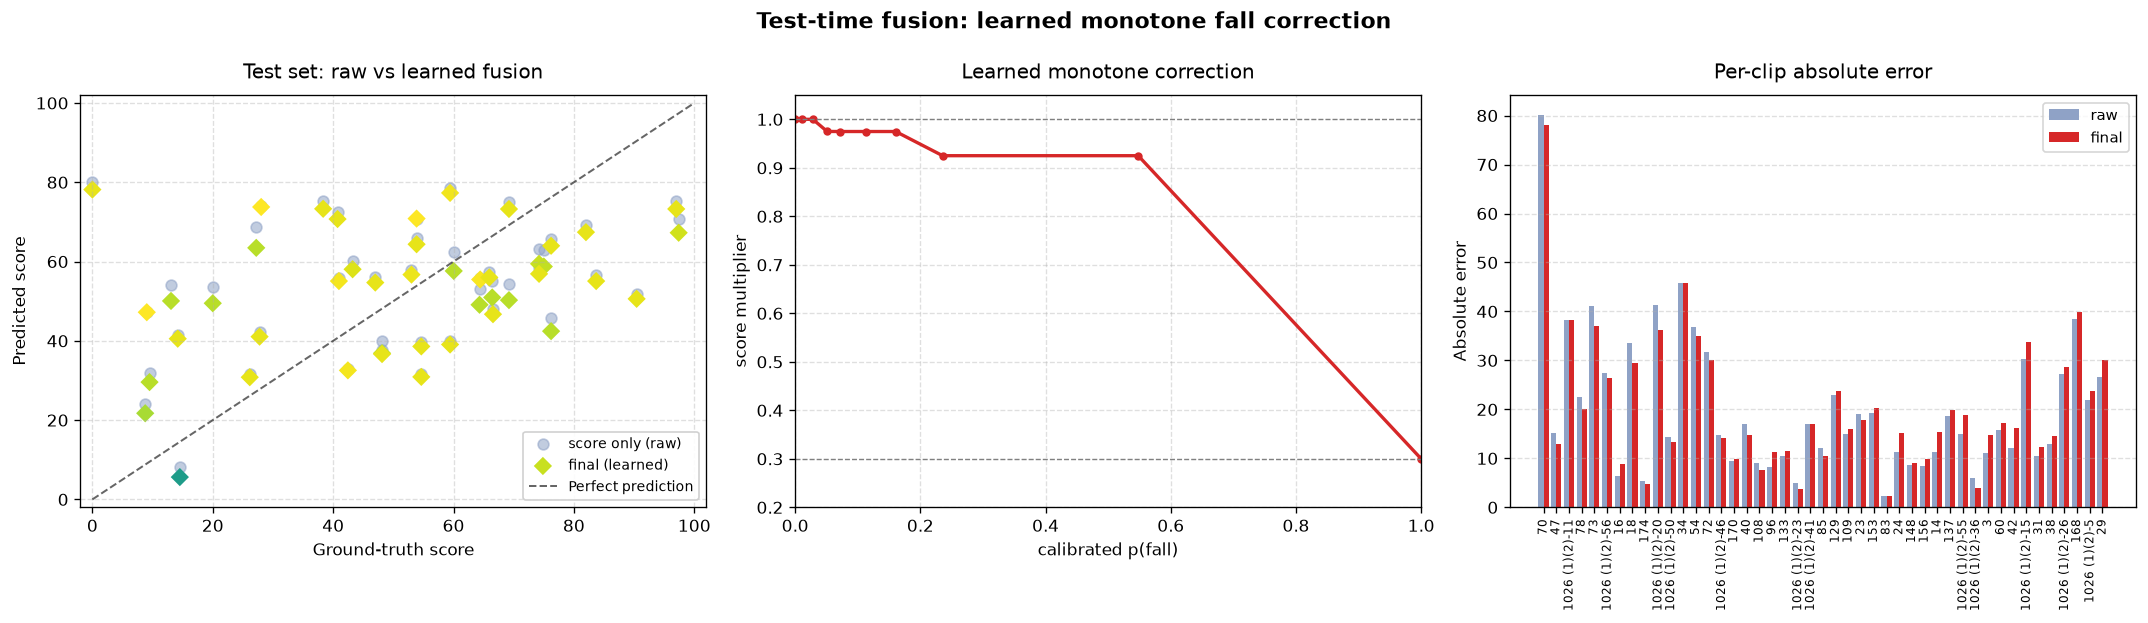


Saved fused predictions -> C:\Users\franc\Downloads\AQA-7\AQA-7\Actions\ski_big_air\checkpoints_3dcnn


In [11]:
# --- 8E. Test-time fusion: learned monotone fall correction ----------------
# Final prediction for each test clip:
#   1) fall classifier (8A) -> p_fall, calibrated on out-of-fold CV predictions
#   2) score regressor (8C) -> raw score
#   3) learned correction: final = raw * m(p_fall)
#      m() is a monotone (non-increasing) curve fitted on the OOF validation
#      predictions, with m(0) = 1 (no change) and m(1) = FALL_SCORE_MULTIPLIER.
#      It is built by choosing the MAE-optimal multiplier per p_fall bin, then
#      pooling adjacent violators (isotonic regression) so the curve is monotone.
#
# Variants reported side by side:
#   learned  : the fitted monotone curve (default)
#   hard     : flag when calibrated p_fall >= threshold, then multiply by 0.3
#   guarded  : hard, but never flag a clip whose raw score exceeds the ceiling
#   soft     : raw * (1 - (1 - multiplier) * p_fall)
#   oracle   : uses the ground-truth fall label (reference only)
#
# Thresholds/bins are selected on the CV validation split, never on test.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import expit
from scipy.stats import pearsonr, spearmanr

FALL_SCORE_MULTIPLIER = 0.3
GATE_SCORE_CEILING = 50.0
LEARNED_BINS = 8
LEARNED_MIN_BIN = 5
FINAL_VARIANT = "learned"        # "learned" | "hard" | "guarded" | "soft"

CKPT_DIR = DATA_DIR / "checkpoints_3dcnn"
fall_npz = np.load(CKPT_DIR / "fall_clf_predictions.npz", allow_pickle=False)
score_npz = np.load(CKPT_DIR / "score_reg_predictions.npz", allow_pickle=False)

test_names = [str(n) for n in fall_npz["test_names"]]
assert test_names == [str(n) for n in score_npz["test_names"]], \
    "fall and score test predictions are misaligned - rerun cells 8A and 8C"

p_test = fall_npz["test_prob"].astype(float)
y_fall_test = fall_npz["test_fall"].astype(int)
y_score_test = score_npz["test_target"].astype(float)
score_test = score_npz["test_pred"].astype(float)

p_val = fall_npz["val_prob"].astype(float)
y_fall_val = fall_npz["val_true"].astype(int)
score_val = score_npz["val_pred"].astype(float)
y_score_val = score_npz["val_target"].astype(float)

assert len(p_val) == len(score_val) == len(y_fall_val) == len(y_score_val), \
    "validation predictions are misaligned - rerun cells 8A and 8C"
print(f"CV validation clips: {len(p_val)} ({int(y_fall_val.sum())} falls) | "
      f"test clips: {len(p_test)} ({int(y_fall_test.sum())} falls)")


# --- 1. Probability calibration (Platt scaling on CV predictions) ----------
def fit_platt(prob, y, l2=1e-2):
    prob = np.clip(np.asarray(prob, dtype=float), 1e-6, 1 - 1e-6)
    z = np.log(prob / (1 - prob))
    y = np.asarray(y, dtype=float)

    def nll(w):
        a, b = w
        q = np.clip(expit(a * z + b), 1e-9, 1 - 1e-9)
        return (-np.mean(y * np.log(q) + (1 - y) * np.log(1 - q))
                + l2 * ((a - 1) ** 2 + b ** 2))

    res = minimize(nll, x0=np.array([1.0, 0.0]), method="Nelder-Mead")
    return float(res.x[0]), float(res.x[1])


def apply_platt(prob, a, b):
    prob = np.clip(np.asarray(prob, dtype=float), 1e-6, 1 - 1e-6)
    return expit(a * np.log(prob / (1 - prob)) + b)


def brier(prob, y):
    return float(np.mean((np.asarray(prob, float) - np.asarray(y, float)) ** 2))


cal_a, cal_b = fit_platt(p_val, y_fall_val)
p_val_cal = apply_platt(p_val, cal_a, cal_b)
p_test_cal = apply_platt(p_test, cal_a, cal_b)

print(f"\nPlatt calibration: a={cal_a:.3f}, b={cal_b:.3f}")
print(f"  Brier score  raw {brier(p_val, y_fall_val):.4f} -> calibrated {brier(p_val_cal, y_fall_val):.4f}")


# --- 2. Metrics ------------------------------------------------------------
def reg_metrics(pred, true):
    pred = np.asarray(pred, dtype=float)
    true = np.asarray(true, dtype=float)
    r = pearsonr(pred, true)[0] if np.std(pred) > 1e-12 else 0.0
    rho = spearmanr(pred, true)[0] if np.std(pred) > 1e-12 else 0.0
    return {"MAE": float(np.abs(pred - true).mean()),
            "RMSE": float(np.sqrt(((pred - true) ** 2).mean())),
            "r": float(r), "rho": float(rho)}


def mae(pred, true):
    return float(np.mean(np.abs(np.asarray(pred) - np.asarray(true))))


# --- 3. Hard / guarded gate (kept for comparison) --------------------------
def gate(score_raw, p_cal, threshold, ceiling=None):
    flagged = p_cal >= threshold
    if ceiling is not None:
        flagged = flagged & (score_raw <= ceiling)
    return np.where(flagged, score_raw * FALL_SCORE_MULTIPLIER, score_raw), flagged


def select_threshold(score_val_, p_val_cal_, y_val_, ceiling=None):
    rows = []
    for t in np.round(np.arange(0.05, 1.00, 0.05), 2):
        pred, flagged = gate(score_val_, p_val_cal_, float(t), ceiling)
        if flagged.sum() == 0:
            continue
        rows.append({"threshold": float(t), "n_flagged": int(flagged.sum()),
                     "MAE": mae(pred, y_val_)})
    table = pd.DataFrame(rows).sort_values(["MAE", "threshold"], ascending=[True, False])
    return float(table.iloc[0]["threshold"]), table


thr_hard, sweep_hard = select_threshold(score_val, p_val_cal, y_score_val)
thr_guarded, sweep_guarded = select_threshold(score_val, p_val_cal, y_score_val,
                                              ceiling=GATE_SCORE_CEILING)


# --- 4. Learned monotone multiplier ----------------------------------------
def _pava_increasing(x, y, w):
    """Pool adjacent violators: weighted, monotone non-decreasing fit."""
    order = np.argsort(x, kind="mergesort")
    xs, ys, ws = x[order], y[order].astype(float), w[order].astype(float)
    blocks = []
    for yi, wi in zip(ys, ws):
        blocks.append([yi * wi, wi, 1])
        while len(blocks) > 1 and (blocks[-2][0] / blocks[-2][1]
                                   > blocks[-1][0] / blocks[-1][1]):
            s1, w1, n1 = blocks.pop()
            s0, w0, n0 = blocks.pop()
            blocks.append([s0 + s1, w0 + w1, n0 + n1])
    fitted = []
    for sw, w_, n_ in blocks:
        fitted.extend([sw / w_] * n_)
    return xs, np.asarray(fitted)


def fit_learned_multiplier(p_cal, score_raw, y_true, multiplier,
                           n_bins=LEARNED_BINS, min_bin=LEARNED_MIN_BIN):
    """Fit a monotone curve m(p) with m(0)=1, m(1)=multiplier.

    For each quantile bin of p we pick the multiplier that minimises MAE on
    the OOF validation clips, then PAVA makes the sequence non-increasing.
    """
    edges = np.quantile(p_cal, np.linspace(0, 1, n_bins + 1))
    edges[0], edges[-1] = 0.0, 1.0
    bin_id = np.clip(np.searchsorted(edges, p_cal, side="right") - 1, 0, n_bins - 1)

    grid = np.linspace(multiplier, 1.0, 141)
    xs, ys, ws = [], [], []
    for k in range(n_bins):
        mask = bin_id == k
        if mask.sum() < min_bin:
            continue
        losses = [np.mean(np.abs(m * score_raw[mask] - y_true[mask])) for m in grid]
        xs.append(float(p_cal[mask].mean()))
        ys.append(-float(grid[int(np.argmin(losses))]))   # negative -> decreasing
        ws.append(int(mask.sum()))

    # anchors: no correction at p=0, full correction at p=1
    xs = np.array([0.0] + xs + [1.0])
    ys = np.array([-1.0] + ys + [-multiplier])
    ws = np.array([1e6] + ws + [1e6], dtype=float)
    x_sorted, fit = _pava_increasing(xs, ys, ws)
    values = np.clip(-fit, multiplier, 1.0)

    def curve(p_new):
        return np.interp(np.asarray(p_new, dtype=float), x_sorted, values,
                         left=values[0], right=values[-1])

    return curve, x_sorted, values


learned_curve, curve_x, curve_y = fit_learned_multiplier(
    p_val_cal, score_val, y_score_val, FALL_SCORE_MULTIPLIER)

mult_val = learned_curve(p_val_cal)
mult_test = learned_curve(p_test_cal)
score_val_learned = score_val * mult_val
score_test_learned = score_test * mult_test

# --- 5. Variants on validation and test -----------------------------------
score_val_hard, flag_val_hard = gate(score_val, p_val_cal, thr_hard)
score_val_guarded, flag_val_guarded = gate(score_val, p_val_cal, thr_guarded,
                                           ceiling=GATE_SCORE_CEILING)
score_val_soft = score_val * (1 - (1 - FALL_SCORE_MULTIPLIER) * p_val_cal)
score_val_oracle = np.where(y_fall_val == 1,
                            score_val * FALL_SCORE_MULTIPLIER, score_val)

score_hard, flag_test_hard = gate(score_test, p_test_cal, thr_hard)
score_guarded, flag_test_guarded = gate(score_test, p_test_cal, thr_guarded,
                                        ceiling=GATE_SCORE_CEILING)
score_soft = score_test * (1 - (1 - FALL_SCORE_MULTIPLIER) * p_test_cal)
score_oracle = np.where(y_fall_test == 1,
                        score_test * FALL_SCORE_MULTIPLIER, score_test)

variants_val = {"raw": score_val, "learned": score_val_learned,
                "hard": score_val_hard, "guarded": score_val_guarded,
                "soft": score_val_soft, "oracle": score_val_oracle}
variants_test = {"raw": score_test, "learned": score_test_learned,
                 "hard": score_hard, "guarded": score_guarded,
                 "soft": score_soft, "oracle": score_oracle}

assert FINAL_VARIANT in variants_val, f"unknown FINAL_VARIANT {FINAL_VARIANT!r}"
score_val_final = variants_val[FINAL_VARIANT]
score_final = variants_test[FINAL_VARIANT]
if FINAL_VARIANT == "learned":
    mult_final = mult_test
elif FINAL_VARIANT == "soft":
    mult_final = 1 - (1 - FALL_SCORE_MULTIPLIER) * p_test_cal
else:
    flag = flag_test_guarded if FINAL_VARIANT == "guarded" else flag_test_hard
    mult_final = np.where(flag, FALL_SCORE_MULTIPLIER, 1.0)

print(f"\nFinal output variant: {FINAL_VARIANT}")
print(f"Gate thresholds chosen on CV: hard {thr_hard:.2f} | guarded {thr_guarded:.2f}")
print(f"Learned multiplier curve: m(0)={curve_y[0]:.2f} -> m(1)={curve_y[-1]:.2f} "
      f"({len(curve_y)} knots)")

print("\nCV validation metrics")
print(pd.DataFrame({name: reg_metrics(pred, y_score_val)
                    for name, pred in variants_val.items()}).T.round(3).to_string())

print("\nCV validation metrics - true score < 20 (the clips the correction targets)")
low = y_score_val < 20
print(pd.DataFrame({name: reg_metrics(pred[low], y_score_val[low])
                    for name, pred in variants_val.items()}).T.round(3).to_string())

print("\nHeld-out test metrics")
print(pd.DataFrame({name: reg_metrics(pred, y_score_test)
                    for name, pred in variants_test.items()}).T.round(3).to_string())

# Gate stats (for the binary variants)
for name, flag in [("hard", flag_test_hard), ("guarded", flag_test_guarded)]:
    tp = int(((flag == 1) & (y_fall_test == 1)).sum())
    fp = int(((flag == 1) & (y_fall_test == 0)).sum())
    fn = int(((flag == 0) & (y_fall_test == 1)).sum())
    print(f"  {name:8s} gate: TP {tp} FP {fp} FN {fn} | "
          f"precision {tp / max(1, tp + fp):.2f} | recall {tp / max(1, tp + fn):.2f}")
print(f"  learned multiplier on test: min {mult_final.min():.2f} | "
      f"median {np.median(mult_final):.2f} | max {mult_final.max():.2f}")

# --- 6. Per-clip table -----------------------------------------------------
detail = pd.DataFrame({
    "filename": test_names,
    "true_score": y_score_test,
    "true_fall": y_fall_test,
    "p_fall_raw": p_test,
    "p_fall_cal": p_test_cal,
    "multiplier": mult_final,
    "score_raw": score_test,
    "score_final": score_final,
    "err_raw": score_test - y_score_test,
    "err_final": score_final - y_score_test,
}).sort_values("true_score")

print("\nPer-clip test predictions")
print(detail.round(3).to_string(index=False))

# --- 7. Plot ---------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), dpi=120)

ax = axes[0]
ax.scatter(y_score_test, score_test, s=42, color="#8fa2c6", alpha=0.55,
           label="score only (raw)")
ax.scatter(y_score_test, score_final, s=60, marker="D", c=mult_final,
           cmap="viridis", vmin=FALL_SCORE_MULTIPLIER, vmax=1.0,
           edgecolor="none", label=f"final ({FINAL_VARIANT})")
ax.plot([0, 100], [0, 100], "k--", alpha=0.6, linewidth=1.2, label="Perfect prediction")
ax.set_xlim(-2, 102); ax.set_ylim(-2, 102)
ax.set_xlabel("Ground-truth score"); ax.set_ylabel("Predicted score")
ax.set_title(f"Test set: raw vs {FINAL_VARIANT} fusion", fontsize=12, pad=10)
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(loc="lower right", fontsize=8.5, framealpha=0.9)

ax = axes[1]
ax.plot(curve_x, curve_y, color="#d62728", linewidth=2.0, marker="o", markersize=4)
ax.axhline(1.0, color="grey", linestyle="--", linewidth=0.8)
ax.axhline(FALL_SCORE_MULTIPLIER, color="grey", linestyle="--", linewidth=0.8)
ax.set_xlim(0, 1); ax.set_ylim(0.2, 1.05)
ax.set_xlabel("calibrated p(fall)")
ax.set_ylabel("score multiplier")
ax.set_title("Learned monotone correction", fontsize=12, pad=10)
ax.grid(True, linestyle="--", alpha=0.4)

ax = axes[2]
x = np.arange(len(detail))
ax.bar(x - 0.2, np.abs(detail["err_raw"]), width=0.4, color="#8fa2c6", label="raw")
ax.bar(x + 0.2, np.abs(detail["err_final"]), width=0.4, color="#d62728", label="final")
ax.set_xticks(x)
ax.set_xticklabels(detail["filename"], rotation=90, fontsize=7)
ax.set_ylabel("Absolute error")
ax.set_title("Per-clip absolute error", fontsize=12, pad=10)
ax.grid(True, axis="y", linestyle="--", alpha=0.4)
ax.legend(fontsize=9)

plt.suptitle("Test-time fusion: learned monotone fall correction",
             fontsize=13, fontweight="bold", y=0.99)
plt.tight_layout()
plt.savefig(DATA_DIR / "fused_test_predictions.png", dpi=150, bbox_inches="tight")
plt.show()

# --- 8. Save ---------------------------------------------------------------
np.savez(
    CKPT_DIR / "fused_test_predictions.npz",
    test_names=np.asarray(test_names),
    true_score=y_score_test.astype(np.float32),
    true_fall=y_fall_test.astype(np.int32),
    p_fall_raw=p_test.astype(np.float32),
    p_fall_cal=p_test_cal.astype(np.float32),
    multiplier=mult_final.astype(np.float32),
    score_raw=score_test.astype(np.float32),
    score_final=score_final.astype(np.float32),
    score_learned=score_test_learned.astype(np.float32),
    score_hard=score_hard.astype(np.float32),
    score_guarded=score_guarded.astype(np.float32),
    score_soft=score_soft.astype(np.float32),
    calibration=np.asarray([cal_a, cal_b], dtype=np.float32),
    threshold_hard=np.float32(thr_hard),
    threshold_guarded=np.float32(thr_guarded),
    curve_x=curve_x.astype(np.float32),
    curve_y=curve_y.astype(np.float32),
    gate_ceiling=np.float32(GATE_SCORE_CEILING),
    fall_score_multiplier=np.float32(FALL_SCORE_MULTIPLIER),
    final_variant=np.asarray(FINAL_VARIANT),
)
detail.to_csv(CKPT_DIR / "fused_test_predictions.csv", index=False)
print(f"\nSaved fused predictions -> {CKPT_DIR}")


Feature caches OK: full 694 keys | windows 468 keys
fold 0: reg MAE 17.36 | y<10 pred  26.7
fold 1: reg MAE 17.76 | y<10 pred  38.2
fold 2: reg MAE 18.23 | y<10 pred  35.5
fold 3: reg MAE 16.57 | y<10 pred  22.7
fold 4: reg MAE 18.67 | y<10 pred  43.0

Near-zero improvement (CV took 17.4s):
              model  oof_mae  oof_r  test_mae  test_r oof_pred_y<10 oof_pred_y<20
 baseline full-clip    16.40   0.56     19.19    0.36          28.2          34.0
end-of-clip + pow25    17.72   0.49     19.25    0.37          33.0          34.6
  end + fall refine    18.40   0.46     18.48    0.43          26.2          30.7

Reference: the y<10 group is 18 clips with true mean 6.11


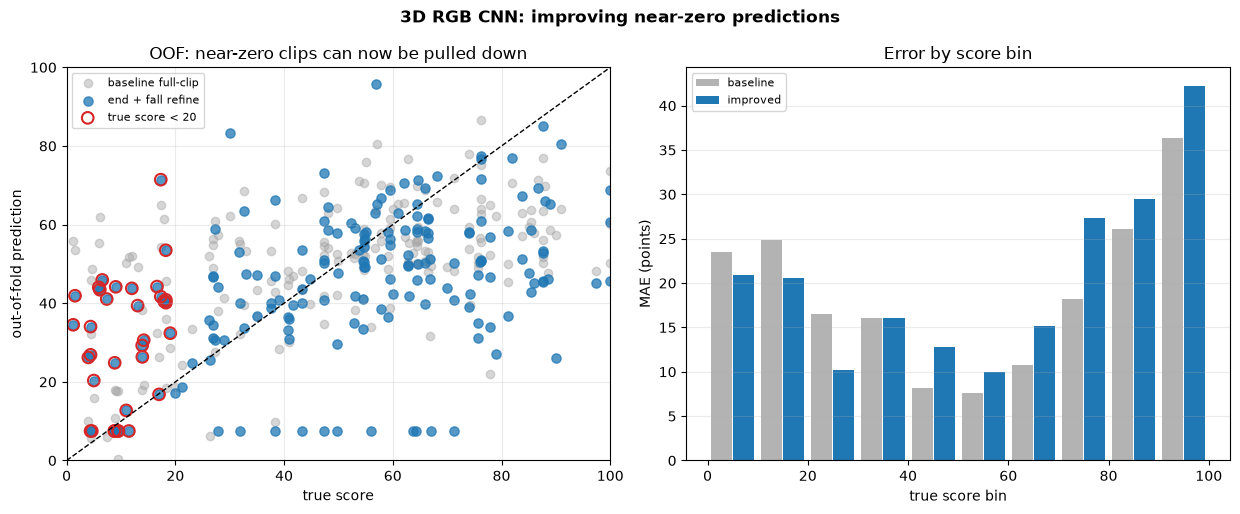

Saved plot -> C:\Users\franc\Downloads\AQA-7\AQA-7\Actions\ski_big_air\low_score_improvement.png

Test clips with true score < 20:
  16           true  14.5 | baseline  24.9 | improved  15.2
  47           true   8.8 | baseline  26.6 | improved  23.9
  70           true   0.0 | baseline  60.9 | improved  75.9
  73           true  13.1 | baseline  51.7 | improved  36.1
  78           true   9.5 | baseline  40.0 | improved  26.5
  1026 (1)(2)-11 true   9.0 | baseline  56.4 | improved   7.5
  1026 (1)(2)-56 true  14.2 | baseline  30.4 | improved  41.7


In [12]:
# --- 9. Improving near-zero scores: end-of-clip features + fall refinement ---
# Diagnosis with the current full-clip model:
#   * clips scored < 10 are predicted around 43 on average (never below ~10)
#   * clips scored >= 90 are predicted around 54
# The cause is regression to the mean plus global average pooling over the whole
# clip, which dilutes a fall that happens in the last second.
#
# Fix:
#   1) append features from the LAST 8 and LAST 4 frames (where the fall occurs)
#   2) use a pow25 target transform so MSE cares proportionally more about lows
#   3) optionally train a fall head (target < 15) and pull the score down when
#      it fires. Set USE_FALL_REFINE=False to keep the plain regressor.
#
# The section is additive: the baseline cells above are untouched.
import os
import time
import multiprocessing

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models.video as models_video
import torchvision.transforms.functional as TF
import decord
from scipy.stats import pearsonr, spearmanr

# --- Config ---------------------------------------------------------------
END_WINDOWS = ("last8", "last4")
TARGET_TRANSFORM = "pow25"      # identity | sqrt | pow25
USE_FALL_REFINE = True
FALL_MODE = "gate"              # "blend" (soft) or "gate" (snap confident falls down)
FALL_TAU = 0.55                 # gate threshold on p(fall)
FALL_THRESHOLD = 10.0           # clips below this are "falls" for the auxiliary head
FALL_ALPHA = 0.9                # blend strength (blend mode only)
FALL_ANCHOR = 7.5               # score used when the fall head is confident
SEED = 42
K_FOLDS = 5
# Adapt to available cache views (clean full video frames: (0,))
TRAIN_VIEWS = (0,)
HEAD_EPOCHS = 250
HEAD_PATIENCE = 40
HEAD_BATCH = 64
HEAD_LR = 6e-3
HEAD_WD = 1e-3

torch.set_num_threads(max(1, multiprocessing.cpu_count() - 2))
device = torch.device("cpu")

DATA_DIR = DATA_DIR if "DATA_DIR" in globals() else os.path.abspath(".")
DATA_DIR = os.path.abspath(DATA_DIR)
CKPT_DIR = os.path.join(DATA_DIR, "checkpoints_3dcnn")
FULL_CACHE = os.path.join(CKPT_DIR, "r3d18_feature_cache_v1.npz")
WINDOW_CACHE = os.path.join(CKPT_DIR, "r3d18_window_cache_v1.npz")

splits = pd.read_csv(os.path.join(DATA_DIR, "splits.csv"), dtype={"filename": str})
train_val_df = splits[splits["split"] != "test"].reset_index(drop=True)
test_df = splits[splits["split"] == "test"].reset_index(drop=True)


def _fold_ids(targets, n=K_FOLDS, seed=SEED):
    bins = pd.qcut(pd.Series(targets).rank(method="first"), n, labels=False).to_numpy()
    ids = np.empty(len(targets), int)
    rng = np.random.default_rng(seed)
    for b in range(n):
        idx = np.flatnonzero(bins == b)
        rng.shuffle(idx)
        ids[idx] = np.arange(len(idx)) % n
    return ids


fold_ids = _fold_ids(train_val_df["target"])
Y_TV = train_val_df["target"].to_numpy(np.float64)
Y_TE = test_df["target"].to_numpy(np.float64)


# --- 9.1 Build / load the end-of-clip feature cache ------------------------
def _find_video(stem):
    for name in (f"{stem}.mp4", f"{stem.zfill(3)}.mp4",
                 f"{stem.zfill(3)}.avi", f"{stem}.avi"):
        p = os.path.join(DATA_DIR, name)
        if os.path.isfile(p):
            return p
    raise FileNotFoundError(stem)


def _load_window_frames(stem, n_frames=8, img_size=112):
    """Load the final n_frames directly from the full-length video (no 16-frame downsampling)."""
    vr = decord.VideoReader(_find_video(stem))
    total_len = len(vr)
    start_idx = max(0, total_len - n_frames)
    idx = list(range(start_idx, total_len))
    while len(idx) < n_frames:
        idx.insert(0, idx[0])
    frames = torch.from_numpy(vr.get_batch(idx).asnumpy())
    x = frames.permute(0, 3, 1, 2).float() / 255.0
    x = TF.resize(x, [img_size, img_size])
    return TF.normalize(x, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

_load_clip_frames = _load_window_frames


def build_window_cache():
    """Extract r3d_18 features for the actual last 8 / last 4 frames of every full clip."""
    backbone = models_video.r3d_18(weights=models_video.R3D_18_Weights.DEFAULT)
    backbone.fc = nn.Identity()
    backbone.eval()

    names = pd.concat([train_val_df, test_df], ignore_index=True)["filename"].astype(str).tolist()
    window_sizes = {"last8": 8, "last4": 4}
    keys, blocks = [], []
    t0 = time.time()
    for window, n_f in window_sizes.items():
        rows = []
        for start in range(0, len(names), 4):
            chunk = names[start:start + 4]
            xb = torch.stack([_load_window_frames(n, n_frames=n_f) for n in chunk])
            xb = xb.permute(0, 2, 1, 3, 4).contiguous()
            with torch.no_grad():
                rows.append(backbone(xb).flatten(1).numpy().astype(np.float32))
        F = np.concatenate(rows, 0)
        keys.extend([f"{n}|{window}" for n in names])
        blocks.append(F)
        print(f"  {window}: {F.shape} | {time.time() - t0:.0f}s")
    np.savez_compressed(WINDOW_CACHE, keys=np.array(keys),
                        features=np.concatenate(blocks, 0))
    print(f"  saved {WINDOW_CACHE}")


def load_npz(path):
    with np.load(path, allow_pickle=False) as z:
        return {str(k): v for k, v in zip(z["keys"], z["features"])}


assert os.path.exists(FULL_CACHE), (
    f"Missing {FULL_CACHE}. Run the fast 3D CNN CV cell first.")
FULL = load_npz(FULL_CACHE)

# The caches are keyed by filename, so they must be regenerated whenever the
# label table grows. Check coverage up front instead of failing with a
# KeyError deep inside feature_row().
ALL_NAMES = pd.concat([train_val_df, test_df], ignore_index=True)["filename"].astype(str)
REQUIRED_FULL = ({f"{n}|{v}" for n in train_val_df["filename"].astype(str)
                  for v in TRAIN_VIEWS}
                 | {f"{n}|0" for n in test_df["filename"].astype(str)})
missing_full = sorted(REQUIRED_FULL - set(FULL))
assert not missing_full, (
    f"Full-clip feature cache is missing {len(missing_full)} entr(ies) "
    f"(e.g. {missing_full[:3]}). Delete {FULL_CACHE} and rerun the fast CV cell."
)

REQUIRED_WIN = {f"{n}|{w}" for n in ALL_NAMES for w in END_WINDOWS}
WIN = load_npz(WINDOW_CACHE) if os.path.exists(WINDOW_CACHE) else None
missing_win = REQUIRED_WIN - set(WIN or {})
if missing_win:
    print(f"[WARN] end-of-clip cache is stale: {len(missing_win)} required "
          f"entr(ies) missing - rebuilding (one-time, ~2 min)...")
    build_window_cache()
    WIN = load_npz(WINDOW_CACHE)
    still_missing = REQUIRED_WIN - set(WIN)
    assert not still_missing, (
        f"Window cache is still missing {len(still_missing)} entr(ies) after "
        f"rebuild (e.g. {sorted(still_missing)[:3]})."
    )
print(f"Feature caches OK: full {len(FULL)} keys | windows {len(WIN)} keys")


# --- 9.2 Feature matrices --------------------------------------------------
def feature_row(stem, view):
    return np.concatenate([FULL[f"{stem}|{view}"]] +
                          [WIN[f"{stem}|{w}"] for w in END_WINDOWS])


X_tr = np.stack([feature_row(n, v)
                 for n in train_val_df["filename"].astype(str)
                 for v in TRAIN_VIEWS])
Y_tr = np.repeat(Y_TV, len(TRAIN_VIEWS))
REP = np.repeat(fold_ids, len(TRAIN_VIEWS))   # fold id of each repeated row

X_va_all = np.stack([feature_row(n, 0) for n in train_val_df["filename"].astype(str)])
X_te = np.stack([feature_row(n, 0) for n in test_df["filename"].astype(str)])
X_last8_tv = np.stack([WIN[f"{n}|last8"] for n in train_val_df["filename"].astype(str)])
X_last8_te = np.stack([WIN[f"{n}|last8"] for n in test_df["filename"].astype(str)])


class MLP(nn.Module):
    def __init__(self, d, out_dim=1, dropout=0.5):
        super().__init__()
        self.net = nn.Sequential(
            nn.Dropout(dropout), nn.Linear(d, 64), nn.ReLU(inplace=True),
            nn.Dropout(dropout), nn.Linear(64, out_dim))

    def forward(self, x):
        return self.net(x).squeeze(-1)


def _fwd_transform(y):
    if TARGET_TRANSFORM == "sqrt":
        return np.sqrt(np.clip(y, 0, None))
    if TARGET_TRANSFORM == "pow25":
        return np.power(np.clip(y, 0, None) / 100.0, 0.25) * 100.0
    return y


def _inv_transform(z):
    if TARGET_TRANSFORM == "sqrt":
        return z ** 2
    if TARGET_TRANSFORM == "pow25":
        return np.power(np.clip(z, 0, None) / 100.0, 4.0) * 100.0
    return z


def train_regressor(Xtr, ytr, Xva, yva, seed):
    mu = Xtr.mean(0, keepdims=True)
    sd = Xtr.std(0, keepdims=True) + 1e-6
    Xt = torch.from_numpy(np.ascontiguousarray((Xtr - mu) / sd))
    Xv = torch.from_numpy(np.ascontiguousarray((Xva - mu) / sd))
    z = _fwd_transform(ytr)
    z_mean, z_std = z.mean(), z.std() + 1e-6
    zt = torch.from_numpy(((z - z_mean) / z_std).astype(np.float32))

    torch.manual_seed(seed)
    model = MLP(Xtr.shape[1])
    opt = torch.optim.AdamW(model.parameters(), lr=HEAD_LR, weight_decay=HEAD_WD)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=10)
    best, best_state, bad = float("inf"), None, 0

    def predict(xb):
        with torch.no_grad():
            raw = model(xb).numpy() * z_std + z_mean
        return np.clip(_inv_transform(raw), 0.0, 100.0)

    for epoch in range(HEAD_EPOCHS):
        model.train()
        perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), HEAD_BATCH):
            idx = perm[i:i + HEAD_BATCH]
            opt.zero_grad(set_to_none=True)
            F.mse_loss(model(Xt[idx]), zt[idx]).backward()
            opt.step()
        model.eval()
        mae = float(np.mean(np.abs(predict(Xv) - yva)))
        sched.step(mae)
        if mae < best - 1e-4:
            best, bad = mae, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= HEAD_PATIENCE:
                break
    model.load_state_dict(best_state)
    model.eval()
    return model, (mu, sd, z_mean, z_std)


def train_fall_head(Xtr, ytr, seed, epochs=200):
    mu = Xtr.mean(0, keepdims=True)
    sd = Xtr.std(0, keepdims=True) + 1e-6
    Xt = torch.from_numpy(np.ascontiguousarray((Xtr - mu) / sd))
    yt = torch.from_numpy(ytr.astype(np.float32))
    pos = float(ytr.sum())
    pw = torch.tensor((len(ytr) - pos) / max(pos, 1.0))

    torch.manual_seed(seed)
    model = MLP(Xtr.shape[1], 1, dropout=0.3)
    opt = torch.optim.AdamW(model.parameters(), lr=HEAD_LR, weight_decay=HEAD_WD)
    for _ in range(epochs):
        model.train()
        perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), HEAD_BATCH):
            idx = perm[i:i + HEAD_BATCH]
            opt.zero_grad(set_to_none=True)
            F.binary_cross_entropy_with_logits(model(Xt[idx]), yt[idx],
                                               pos_weight=pw).backward()
            opt.step()
    model.eval()
    return model, (mu, sd)


def predict_reg(model, scaler, X):
    mu, sd, z_mean, z_std = scaler
    with torch.no_grad():
        raw = model(torch.from_numpy(np.ascontiguousarray((X - mu) / sd))).numpy()
    return np.clip(_inv_transform(raw * z_std + z_mean), 0.0, 100.0)


def predict_fall(model, scaler, X):
    mu, sd = scaler
    with torch.no_grad():
        return torch.sigmoid(model(torch.from_numpy(
            np.ascontiguousarray((X - mu) / sd)))).numpy()


def reg_metrics(pred, true):
    pred, true = np.asarray(pred, float), np.asarray(true, float)
    return {
        "mae": float(np.mean(np.abs(pred - true))),
        "rmse": float(np.sqrt(np.mean((pred - true) ** 2))),
        "pearson": float(pearsonr(pred, true)[0]) if np.std(pred) > 0 else float("nan"),
        "spearman": float(spearmanr(pred, true)[0]) if np.std(pred) > 0 else float("nan"),
    }


# --- 9.3 5-fold CV: regressor + optional fall head -------------------------
reg_oof = np.full(len(train_val_df), np.nan)
p_fall_oof = np.full(len(train_val_df), np.nan)
reg_test_folds, p_fall_test_folds = [], []
y_fall = (Y_TV < FALL_THRESHOLD).astype(int)
t0 = time.time()

for fold in range(K_FOLDS):
    tr = REP != fold
    va = fold_ids == fold
    fit = fold_ids != fold

    model, scaler = train_regressor(X_tr[tr], Y_tr[tr], X_va_all[va], Y_TV[va], SEED + fold)
    reg_oof[va] = predict_reg(model, scaler, X_va_all[va])
    reg_test_folds.append(predict_reg(model, scaler, X_te))
    torch.save({"state_dict": model.state_dict(), "mean": scaler[0], "std": scaler[1],
                "z_mean": scaler[2], "z_std": scaler[3], "transform": TARGET_TRANSFORM,
                "windows": list(END_WINDOWS), "in_dim": X_tr.shape[1]},
               os.path.join(CKPT_DIR, f"end_head_fold{fold}.pth"))

    if USE_FALL_REFINE:
        fall_model, fall_scaler = train_fall_head(X_last8_tv[fit], y_fall[fit], SEED + fold)
        p_fall_oof[va] = predict_fall(fall_model, fall_scaler, X_last8_tv[va])
        p_fall_test_folds.append(predict_fall(fall_model, fall_scaler, X_last8_te))
        torch.save({"state_dict": fall_model.state_dict(),
                    "mean": fall_scaler[0], "std": fall_scaler[1],
                    "threshold": FALL_THRESHOLD},
                   os.path.join(CKPT_DIR, f"fall_head_fold{fold}.pth"))

    print(f"fold {fold}: reg MAE {np.mean(np.abs(reg_oof[va] - Y_TV[va])):5.2f} | "
          f"y<10 pred {reg_oof[va][Y_TV[va] < 10].mean() if (Y_TV[va] < 10).any() else float('nan'):5.1f}")

reg_test = np.mean(reg_test_folds, 0)
if USE_FALL_REFINE:
    p_fall_test = np.mean(p_fall_test_folds, 0)
    if FALL_MODE == "gate":
        pred_oof = np.where(p_fall_oof >= FALL_TAU, FALL_ANCHOR, reg_oof)
        pred_test = np.where(p_fall_test >= FALL_TAU, FALL_ANCHOR, reg_test)
    else:
        pred_oof = np.clip((1 - FALL_ALPHA * p_fall_oof) * reg_oof
                           + (FALL_ALPHA * p_fall_oof) * FALL_ANCHOR, 0, 100)
        pred_test = np.clip((1 - FALL_ALPHA * p_fall_test) * reg_test
                            + (FALL_ALPHA * p_fall_test) * FALL_ANCHOR, 0, 100)
else:
    pred_oof, pred_test = reg_oof, reg_test

# --- Baseline (full-clip sigmoid heads from cell 5) for comparison ---------
class BaselineHead(nn.Module):
    """Mirror of the MLP head saved by the fast CV cell (any depth)."""
    def __init__(self, in_dim=512, hidden=(256, 64), dropout=0.5):
        super().__init__()
        layers = [nn.Dropout(dropout)]
        prev = in_dim
        for width in hidden:
            layers += [nn.Linear(prev, width), nn.ReLU(inplace=True),
                       nn.Dropout(dropout)]
            prev = width
        layers += [nn.Linear(prev, 1), nn.Sigmoid()]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)


def load_baseline_head(path):
    ckpt = torch.load(path, map_location="cpu", weights_only=True)
    sd = ckpt["state_dict"]
    in_dim = sd["net.1.weight"].shape[1]
    idx = sorted(int(k.split(".")[1]) for k in sd
                 if k.startswith("net.") and k.endswith(".weight") and sd[k].dim() == 2)
    hidden = tuple(sd[f"net.{i}.weight"].shape[0] for i in idx[:-1])
    head = BaselineHead(in_dim, hidden=hidden, dropout=0.5)
    head.load_state_dict(sd)
    head.eval()
    return head, ckpt["mean"].numpy(), ckpt["std"].numpy()


X_full_va = np.stack([FULL[f"{n}|0"] for n in train_val_df["filename"].astype(str)])
X_full_te = np.stack([FULL[f"{n}|0"] for n in test_df["filename"].astype(str)])
base_oof = np.full(len(train_val_df), np.nan)
base_test_folds = []
for fold in range(K_FOLDS):
    path = os.path.join(CKPT_DIR, f"best_head_fold{fold}.pth")
    if not os.path.exists(path):
        base_oof = None
        break
    head, mean, std = load_baseline_head(path)
    va = fold_ids == fold
    with torch.no_grad():
        base_oof[va] = head(torch.from_numpy(
            np.ascontiguousarray((X_full_va[va] - mean) / std))).numpy() * 100.0
        base_test_folds.append(head(torch.from_numpy(
            np.ascontiguousarray((X_full_te - mean) / std))).numpy() * 100.0)
base_test = np.mean(base_test_folds, 0) if base_test_folds else None

# --- Report ----------------------------------------------------------------
def low_stats(pred, true, thr):
    m = true < thr
    return f"{(pred[m].mean() if m.any() else float('nan')):5.1f}"


rows = []
if base_oof is not None:
    mb, mt = reg_metrics(base_oof, Y_TV), reg_metrics(base_test, Y_TE)
    rows.append({"model": "baseline full-clip", "oof_mae": mb["mae"], "oof_r": mb["pearson"],
                 "test_mae": mt["mae"], "test_r": mt["pearson"],
                 "oof_pred_y<10": low_stats(base_oof, Y_TV, 10),
                 "oof_pred_y<20": low_stats(base_oof, Y_TV, 20)})
mr, mtr = reg_metrics(reg_oof, Y_TV), reg_metrics(reg_test, Y_TE)
rows.append({"model": "end-of-clip + pow25", "oof_mae": mr["mae"], "oof_r": mr["pearson"],
             "test_mae": mtr["mae"], "test_r": mtr["pearson"],
             "oof_pred_y<10": low_stats(reg_oof, Y_TV, 10),
             "oof_pred_y<20": low_stats(reg_oof, Y_TV, 20)})
if USE_FALL_REFINE:
    mp, mtp = reg_metrics(pred_oof, Y_TV), reg_metrics(pred_test, Y_TE)
    rows.append({"model": "end + fall refine", "oof_mae": mp["mae"], "oof_r": mp["pearson"],
                 "test_mae": mtp["mae"], "test_r": mtp["pearson"],
                 "oof_pred_y<10": low_stats(pred_oof, Y_TV, 10),
                 "oof_pred_y<20": low_stats(pred_oof, Y_TV, 20)})

print(f"\nNear-zero improvement (CV took {time.time() - t0:.1f}s):")
print(pd.DataFrame(rows).round(2).to_string(index=False))
print("\nReference: the y<10 group is", int((Y_TV < 10).sum()),
      "clips with true mean", round(float(Y_TV[Y_TV < 10].mean()), 2))

# --- Plot ------------------------------------------------------------------
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2))
ax = axes[0]
if base_oof is not None:
    ax.scatter(Y_TV, base_oof, s=36, alpha=0.45, color="0.65", label="baseline full-clip")
ax.scatter(Y_TV, pred_oof, s=44, alpha=0.75, color="tab:blue",
           label="end + fall refine" if USE_FALL_REFINE else "end-of-clip")
low = Y_TV < 20
ax.scatter(Y_TV[low], pred_oof[low], s=70, facecolors="none", edgecolors="tab:red",
           linewidths=1.5, label="true score < 20")
ax.plot([0, 100], [0, 100], "k--", lw=1)
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_xlabel("true score"); ax.set_ylabel("out-of-fold prediction")
ax.set_title("OOF: near-zero clips can now be pulled down")
ax.legend(fontsize=8); ax.grid(alpha=0.25)

# MAE by true-score bin, baseline vs full pipeline
edges = np.arange(0, 101, 10)
centers = edges[:-1] + 5
base_bins, new_bins = [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    m = (Y_TV >= lo) & (Y_TV < hi)
    base_bins.append(np.mean(np.abs(base_oof[m] - Y_TV[m])) if base_oof is not None and m.any() else np.nan)
    new_bins.append(np.mean(np.abs(pred_oof[m] - Y_TV[m])) if m.any() else np.nan)
ax = axes[1]
ax.bar(centers - 2.2, base_bins, width=4.2, label="baseline", color="0.7")
ax.bar(centers + 2.2, new_bins, width=4.2, label="improved", color="tab:blue")
ax.set_xlabel("true score bin"); ax.set_ylabel("MAE (points)")
ax.set_title("Error by score bin")
ax.legend(fontsize=8); ax.grid(alpha=0.25, axis="y")

fig.suptitle("3D RGB CNN: improving near-zero predictions", fontweight="bold")
fig.tight_layout()
out = os.path.join(DATA_DIR, "low_score_improvement.png")
fig.savefig(out, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved plot -> {out}")

print("\nTest clips with true score < 20:")
m = Y_TE < 20
for name, y, b, r in zip(test_df["filename"].astype(str)[m], Y_TE[m],
                         (base_test[m] if base_test is not None else np.full(m.sum(), np.nan)),
                         (pred_test[m])):
    print(f"  {name:12s} true {y:5.1f} | baseline {b:5.1f} | improved {r:5.1f}")

## YOLO pose pipeline (cached keypoints + augmented training)

Keypoints are extracted with YOLOv8-Pose **once** per clip and cached as normalised `(N_frames, 17, 3)` arrays (`x`, `y`, `confidence`). The dataset cell below adds clip-level augmentation **only for the training split**: horizontal flip with L/R joint swap, temporal crop/resample, speed jitter, small scale/translation jitter, keypoint noise, and joint dropout. Validation and test clips remain unaugmented.


In [13]:
# --- 1. Pose cache: extract once, reuse for every epoch ------------------
# Frames are decoded full-length, every detected person's keypoints are
# normalized to [0, 1] image coordinates, and the keypoint confidence is kept
# as a third channel so missing joints are distinguishable from (0, 0).
# Cache layout: pose_cache/<filename>.npz  ->  pose (N_frames, 17, 3), fps, width, height
import time
import decord
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from ultralytics import YOLO

DATA_DIR = Path("C:/Users/franc/Downloads/AQA-7/AQA-7/Actions/ski_big_air")
CACHE_DIR = DATA_DIR / "pose_cache"
CACHE_DIR.mkdir(exist_ok=True)

POSE_WEIGHTS = "yolov8n-pose.pt"
POSE_CONF = 0.25
POSE_IMGSZ = 640        # detection resolution; keypoints are normalized afterwards
FRAME_BATCH = 32        # frames per YOLO call
MIN_FRAMES = 16         # clips shorter than this are unusable, skip them
CACHE_VERSION = 2       # bump whenever POSE_* settings change
DEVICE = 0 if torch.cuda.is_available() else "cpu"

pose_model = YOLO(POSE_WEIGHTS)


def find_video(stem):
    """Resolve a label stem to its .mp4/.avi file (numeric labels are zero-padded)."""
    stem = str(stem)
    for name in (f"{stem}.mp4", f"{stem.zfill(3)}.mp4",
                 f"{stem.zfill(3)}.avi", f"{stem}.avi"):
        candidate = DATA_DIR / name
        if candidate.is_file():
            return candidate
    return None


def cache_is_current(out_path, video_path):
    """True only if the cache was built with the current settings and is newer than the video."""
    if not out_path.exists() or out_path.stat().st_mtime < video_path.stat().st_mtime:
        return False
    try:
        with np.load(out_path) as cached:
            return (int(cached["version"]) == CACHE_VERSION
                    and int(cached["imgsz"]) == POSE_IMGSZ
                    and float(cached["conf"]) == POSE_CONF
                    and str(cached["weights"]) == POSE_WEIGHTS)
    except Exception:
        return False


def extract_pose(video_path):
    """Return (N, 17, 3): normalized x, y, keypoint confidence for every frame."""
    vr = decord.VideoReader(str(video_path))
    n = len(vr)
    height, width = vr[0].shape[:2]
    pose = np.zeros((n, 17, 3), dtype=np.float32)

    for start in range(0, n, FRAME_BATCH):
        frames = vr.get_batch(np.arange(start, min(start + FRAME_BATCH, n))).asnumpy()
        results = pose_model(list(frames), verbose=False, conf=POSE_CONF,
                             imgsz=POSE_IMGSZ, device=DEVICE)

        for offset, result in enumerate(results):
            keypoints = result.keypoints
            if keypoints is None or keypoints.xy is None or len(keypoints.xy) == 0:
                continue

            # Pick the largest detected person: the main subject, not a spectator.
            if result.boxes is not None and len(result.boxes) > 0:
                wh = result.boxes.xywh[:, 2:4]
                person = int(torch.argmax(wh[:, 0] * wh[:, 1]).item())
            else:
                person = 0

            xy = keypoints.xy[person].cpu().numpy()
            conf = (keypoints.conf[person].cpu().numpy()
                    if keypoints.conf is not None else np.ones(17, dtype=np.float32))

            frame_idx = start + offset
            pose[frame_idx, :, 0] = np.clip(xy[:, 0] / width, 0.0, 1.0)
            pose[frame_idx, :, 1] = np.clip(xy[:, 1] / height, 0.0, 1.0)
            pose[frame_idx, :, 2] = conf

    return pose


def build_pose_cache(csv_file="filtered_labels.csv", force=False):
    """Extract every clip listed in csv_file once. Resumable; stale caches are rebuilt."""
    csv_path = Path(csv_file)
    if not csv_path.is_absolute():
        csv_path = DATA_DIR / csv_path
    df = pd.read_csv(csv_path, sep=",")

    jobs, skipped = [], []
    for stem in df["filename"].astype(str):
        video_path = find_video(stem)
        out_path = CACHE_DIR / f"{stem}.npz"
        if video_path is None:
            skipped.append((stem, None, "video missing"))
            continue
        try:
            n_frames = len(decord.VideoReader(str(video_path)))
        except Exception as exc:
            skipped.append((stem, None, f"decode error: {exc}"))
            continue
        if n_frames < MIN_FRAMES:
            skipped.append((stem, n_frames, f"too short ({n_frames} frames)"))
            continue
        if not force and cache_is_current(out_path, video_path):
            continue
        jobs.append((stem, video_path, n_frames))

    print(f"cache: {len(jobs)} to extract, "
          f"{len(df) - len(jobs) - len(skipped)} up to date, {len(skipped)} skipped")
    if skipped:
        for stem, _, reason in skipped:
            print(f"  [SKIP] {stem}: {reason}")

    t0 = time.time()
    log = []
    for i, (stem, video_path, n_frames) in enumerate(jobs, 1):
        clip_start = time.time()
        try:
            pose = extract_pose(video_path)
            vr = decord.VideoReader(str(video_path))
            height, width = vr[0].shape[:2]
            np.savez_compressed(
                CACHE_DIR / f"{stem}.npz",
                pose=pose,
                fps=np.float32(vr.get_avg_fps()),
                width=width,
                height=height,
                version=CACHE_VERSION,
                imgsz=POSE_IMGSZ,
                conf=POSE_CONF,
                weights=POSE_WEIGHTS,
            )
            detected = int((pose[:, :, 2] > 0.1).any(axis=1).sum())
            log.append({"filename": stem, "frames": len(pose),
                        "detected_frames": detected, "status": "ok"})
        except Exception as exc:
            log.append({"filename": stem, "frames": n_frames,
                        "detected_frames": 0, "status": f"error: {exc}"})

        if i % 10 == 0 or i == len(jobs):
            elapsed = time.time() - t0
            per_clip = elapsed / i
            print(f"  [{i}/{len(jobs)}] {stem} | {per_clip:.1f}s/clip, "
                  f"ETA {(len(jobs) - i) * per_clip / 60:.1f} min")

    for stem, n_frames, reason in skipped:
        log.append({"filename": stem, "frames": n_frames,
                    "detected_frames": 0, "status": reason})
    if log:
        pd.DataFrame(log).to_csv(CACHE_DIR / "build_log.csv", sep=",", index=False)
    print(f"done in {(time.time() - t0) / 60:.1f} min; "
          f"{len(list(CACHE_DIR.glob('*.npz')))} cache files in {CACHE_DIR}")


build_pose_cache()   # pass force=True after changing POSE_* settings


cache: 0 to extract, 203 up to date, 0 skipped
done in 0.0 min; 234 cache files in C:\Users\franc\Downloads\AQA-7\AQA-7\Actions\ski_big_air\pose_cache


In [14]:
# --- 2. Fixed-length pose dataset + augmented training samples ------------
# Reuses the shared, already-built split table (splits.csv). Do NOT regenerate
# it here: the RGB pipeline uses the same file, and re-splitting would silently
# invalidate those train/val/test assignments.
#
# Every clip comes from pose_cache/<filename>.npz as (N_frames, 17, 3):
#   x, y  -> image coordinates normalised to [0, 1]
#   conf  -> YOLO keypoint confidence (0 = joint missing)
#
# Training split is wrapped in PoseAugmenter; val/test stay clean.
import random

import numpy as np
import pandas as pd
import torch
from pathlib import Path
from torch.utils.data import DataLoader, Dataset

DATA_DIR = Path("C:/Users/franc/Downloads/AQA-7/AQA-7/Actions/ski_big_air")
CACHE_DIR = DATA_DIR / "pose_cache"
SPLITS_CSV = DATA_DIR / "splits.csv"

NUM_FRAMES = 64          # every clip becomes (64, 17, 3)
SEED = 42
BATCH_SIZE = 16

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# COCO-17 left/right joint pairs, used by the mirror augmentation
FLIP_INDEX = np.array([0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13, 16, 15],
                      dtype=np.int64)


class PoseAugmenter:
    """Clip-level augmentation for cached skeletons of shape (T, 17, 3).

    All augmentations are applied consistently across the whole clip so the
    motion stays coherent. Geometry is kept in normalised [0, 1] coordinates.
    """

    def __init__(
        self,
        p_flip=0.5,
        p_temporal=0.5,
        p_speed=0.4,
        p_scale=0.5,
        p_noise=0.5,
        p_joint_drop=0.3,
        noise_std=0.006,
        scale_range=(0.90, 1.10),
        shift=0.02,
        joint_drop_prob=0.12,
        min_keep=0.60,
    ):
        self.p_flip = p_flip
        self.p_temporal = p_temporal
        self.p_speed = p_speed
        self.p_scale = p_scale
        self.p_noise = p_noise
        self.p_joint_drop = p_joint_drop
        self.noise_std = noise_std
        self.scale_range = scale_range
        self.shift = shift
        self.joint_drop_prob = joint_drop_prob
        self.min_keep = min_keep

    @staticmethod
    def _time_resample(pose, out_len):
        n = len(pose)
        if n == out_len:
            return pose.astype(np.float32, copy=False)
        src = np.linspace(0, n - 1, out_len)
        lo = np.floor(src).astype(int)
        hi = np.minimum(lo + 1, n - 1)
        w = (src - lo)[:, None, None].astype(np.float32)
        return (pose[lo] * (1.0 - w) + pose[hi] * w).astype(np.float32)

    def _temporal_crop(self, pose):
        """Keep a random contiguous 60-100 % window, resampled to full length."""
        n = len(pose)
        if n < 4:
            return pose
        keep = random.uniform(self.min_keep, 1.0)
        start = random.uniform(0.0, 1.0 - keep)
        lo = int(round(start * n))
        hi = min(n, max(lo + 2, int(round((start + keep) * n))))
        return self._time_resample(pose[lo:hi], n)

    def _speed_jitter(self, pose):
        """Non-uniform time resampling = slightly faster / slower performance."""
        n = len(pose)
        if n < 4:
            return pose
        speed = random.uniform(0.75, 1.25)
        src = (np.linspace(0.0, 1.0, n) ** speed) * (n - 1)
        lo = np.floor(src).astype(int)
        hi = np.minimum(lo + 1, n - 1)
        w = (src - lo)[:, None, None].astype(np.float32)
        return (pose[lo] * (1.0 - w) + pose[hi] * w).astype(np.float32)

    def _horizontal_flip(self, pose):
        """Mirror x and swap left/right joints."""
        pose = pose.copy()
        pose[..., 0] = 1.0 - pose[..., 0]
        return pose[:, FLIP_INDEX, :]

    def _spatial_jitter(self, pose):
        """Small scale / translation jitter around the image centre."""
        scale = random.uniform(*self.scale_range)
        tx = random.uniform(-self.shift, self.shift)
        ty = random.uniform(-self.shift, self.shift)
        pose = pose.copy()
        pose[..., 0] = np.clip((pose[..., 0] - 0.5) * scale + 0.5 + tx, 0.0, 1.0)
        pose[..., 1] = np.clip((pose[..., 1] - 0.5) * scale + 0.5 + ty, 0.0, 1.0)
        return pose

    def _add_noise(self, pose):
        """Detector-like jitter, only on joints that were actually detected."""
        mask = pose[..., 2:3] > 0.1
        noise = np.random.randn(*pose[..., :2].shape).astype(np.float32)
        pose = pose.copy()
        pose[..., :2] = np.clip(pose[..., :2] + noise * self.noise_std * mask,
                                0.0, 1.0)
        return pose

    def _joint_dropout(self, pose):
        """Simulate missing detections for a random subset of joints (whole clip)."""
        drop = np.random.rand(pose.shape[1]) < self.joint_drop_prob
        if drop.any():
            pose = pose.copy()
            pose[:, drop, :2] = 0.0
            pose[:, drop, 2] = 0.0
        return pose

    def __call__(self, pose):
        pose = np.asarray(pose, dtype=np.float32).copy()
        if random.random() < self.p_temporal:
            pose = self._temporal_crop(pose)
        if random.random() < self.p_speed:
            pose = self._speed_jitter(pose)
        if random.random() < self.p_flip:
            pose = self._horizontal_flip(pose)
        if random.random() < self.p_scale:
            pose = self._spatial_jitter(pose)
        if random.random() < self.p_noise:
            pose = self._add_noise(pose)
        if random.random() < self.p_joint_drop:
            pose = self._joint_dropout(pose)
        return np.ascontiguousarray(pose, dtype=np.float32)


class PoseSequenceDataset(Dataset):
    """Fixed-length skeleton sequences from the pose cache.

    `data` is a DataFrame with at least `filename` and `target` columns.
    Set `augment=True` for training splits; val/test should stay clean.
    """

    def __init__(self, data, cache_dir=CACHE_DIR, num_frames=NUM_FRAMES,
                 augment=False, augmenter=None):
        self.data = data.reset_index(drop=True).copy()
        self.cache_dir = Path(cache_dir)
        self.num_frames = num_frames
        self.augment = augment
        self.augmenter = augmenter if augmenter is not None else PoseAugmenter()

        missing = [f for f in self.data["filename"].astype(str)
                   if not (self.cache_dir / f"{f}.npz").exists()]
        if missing:
            raise FileNotFoundError(
                f"{len(missing)} clip(s) have no pose cache: {missing[:5]}. "
                f"Run the cache cell first."
            )

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        stem = str(row["filename"])
        with np.load(self.cache_dir / f"{stem}.npz") as cached:
            pose = cached["pose"]                       # (N_frames, 17, 3)

        if self.augment:
            pose = self.augmenter(pose)

        indices = np.linspace(0, len(pose) - 1, self.num_frames, dtype=int)
        sequence = torch.from_numpy(
            np.ascontiguousarray(pose[indices], dtype=np.float32))
        target = torch.tensor(float(row["target"]), dtype=torch.float32)
        return sequence, target


class CachedPoseDataset(PoseSequenceDataset):
    """PoseSequenceDataset restricted to one split of splits.csv."""

    def __init__(self, split, splits_csv=SPLITS_CSV, num_frames=NUM_FRAMES,
                 augment=False, augmenter=None, cache_dir=CACHE_DIR):
        splits = pd.read_csv(splits_csv, dtype={"filename": str})
        data = splits[splits["split"] == split]
        if not len(data):
            raise ValueError(f"split '{split}' is empty in {splits_csv}")
        super().__init__(data, cache_dir=cache_dir, num_frames=num_frames,
                         augment=augment, augmenter=augmenter)


splits = pd.read_csv(SPLITS_CSV, dtype={"filename": str})
train_augmenter = PoseAugmenter()

train_dataset = CachedPoseDataset("train")
train_dataset_aug = CachedPoseDataset("train", augment=True,
                                      augmenter=train_augmenter)
val_dataset = CachedPoseDataset("val")
test_dataset = CachedPoseDataset("test")

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=0)
train_loader_aug = DataLoader(train_dataset_aug, batch_size=BATCH_SIZE,
                              shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=0)

# --- Sanity checks --------------------------------------------------------
train_names = set(train_dataset.data["filename"].astype(str))
val_names = set(val_dataset.data["filename"].astype(str))
test_names = set(test_dataset.data["filename"].astype(str))
assert not (train_names & val_names or train_names & test_names
            or val_names & test_names), "split leakage"
assert len(train_names) + len(val_names) + len(test_names) == len(splits), \
    "rows lost in split"

for name, dataset in (("train", train_dataset), ("val", val_dataset),
                      ("test", test_dataset)):
    t = dataset.data["target"]
    print(f"{name:5s}: {len(dataset):3d} clips | target mean {t.mean():5.1f} "
          f"std {t.std():5.1f} range {t.min()}-{t.max()}")

xb, yb = next(iter(train_loader))
xa, _ = next(iter(train_loader_aug))
print(f"\nbatch: x {tuple(xb.shape)} (batch, time, joints, x/y/confidence), "
      f"y {tuple(yb.shape)}")
print(f"value ranges: x/y [{xb[:, :, :, :2].min():.3f}, "
      f"{xb[:, :, :, :2].max():.3f}], "
      f"confidence [{xb[:, :, :, 2].min():.3f}, {xb[:, :, :, 2].max():.3f}]")
print(f"targets: {yb[:8].tolist()}")

# The augmented batch should differ from the clean one but keep the same shape.
assert xa.shape == xb.shape
print(f"augmentation: |clean - augmented| mean "
      f"{(xa - xb).abs().mean():.4f} | "
      f"max {(xa - xb).abs().max():.3f}")
print(f"augmented x/y range: [{xa[:, :, :, :2].min():.3f}, "
      f"{xa[:, :, :, :2].max():.3f}]")


train: 164 clips | target mean  50.4 std  25.3 range 1.21256808-100.0
val  :  25 clips | target mean  50.1 std  28.4 range 4.399655232-100.0
test :  45 clips | target mean  50.9 std  25.5 range 0.0-97.40400078

batch: x (16, 64, 17, 3) (batch, time, joints, x/y/confidence), y (16,)
value ranges: x/y [0.000, 1.000], confidence [0.000, 0.998]
targets: [49.64508819580078, 76.20881652832031, 62.79625701904297, 32.66797637939453, 70.0, 79.0, 4.399655342102051, 6.10376501083374]
augmentation: |clean - augmented| mean 0.3501 | max 1.000
augmented x/y range: [0.000, 1.000]


In [15]:
# --- 3. Baseline model: bidirectional GRU over cached poses -------------
# Input:  (batch, 64 frames, 17 joints, x/y/confidence)
# Output: one score in [0, 100]. Targets are scaled by 100 for training only.
# Training uses the augmented pose split; validation/test stay clean.
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from pathlib import Path
from scipy.stats import pearsonr, spearmanr

DATA_DIR = Path("C:/Users/franc/Downloads/AQA-7/AQA-7/Actions/ski_big_air")
CKPT_DIR = DATA_DIR / "checkpoints"
CKPT_DIR.mkdir(exist_ok=True)

SEED = 42
MAX_EPOCHS = 150
PATIENCE = 25
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
TARGET_SCALE = 100.0
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()

# COCO-17 left/right joint pairs, used for horizontal-flip augmentation
FLIP_INDEX = torch.tensor([0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13, 16, 15])


def mask_missing_joints(x):
    """Zero x/y where keypoint confidence is negligible (confidence stays as a feature)."""
    x = x.clone()
    x[..., :2] = x[..., :2] * (x[..., 2:3] > 0.1)
    return x


def flip_poses(x):
    """Mirror x and swap left/right joints. x: (batch, time, 17, 3)."""
    x = x.clone()
    x[..., 0] = 1.0 - x[..., 0]
    return x[:, :, FLIP_INDEX.to(x.device), :]


class PoseGRUBaseline(nn.Module):
    def __init__(self, num_joints=17, in_channels=3, hidden=96, dropout=0.2):
        super().__init__()
        in_dim = num_joints * in_channels
        self.norm = nn.LayerNorm(in_dim)
        self.gru = nn.GRU(in_dim, hidden, batch_first=True, bidirectional=True)
        self.head = nn.Sequential(
            nn.Linear(hidden * 4, 64),   # mean + max pooling over time
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        batch, time, joints, channels = x.shape
        x = self.norm(x.reshape(batch, time, joints * channels))
        out, _ = self.gru(x)
        pooled = torch.cat([out.mean(dim=1), out.amax(dim=1)], dim=1)
        return self.head(pooled).squeeze(-1)


def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    losses, predictions, targets = [], [], []

    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        # Flip / temporal / noise augmentation now happens in the dataset's
        # PoseAugmenter, so the training loop only needs to mask missing joints.
        x = mask_missing_joints(x)

        with torch.set_grad_enabled(training):
            output = model(x)
            loss = criterion(output, y / TARGET_SCALE)
            if training:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 5.0)
                optimizer.step()

        losses.append(loss.item())
        predictions.append((output.detach() * TARGET_SCALE).cpu())
        targets.append(y.detach().cpu())

    predictions = torch.cat(predictions).numpy()
    targets = torch.cat(targets).numpy()
    mae = float(np.mean(np.abs(predictions - targets)))
    return float(np.mean(losses)), mae, predictions, targets


def regression_metrics(y_true, y_pred):
    if np.std(y_pred) == 0 or np.std(y_true) == 0:
        pearson = spearman = float("nan")
    else:
        pearson = float(pearsonr(y_true, y_pred)[0])
        spearman = float(spearmanr(y_true, y_pred)[0])
    return {
        "mae": float(np.mean(np.abs(y_true - y_pred))),
        "rmse": float(np.sqrt(np.mean((y_true - y_pred) ** 2))),
        "pearson": pearson,
        "spearman": spearman,
    }


def evaluate(model, loader):
    criterion = nn.SmoothL1Loss(beta=0.05)
    _, _, predictions, targets = run_epoch(model, loader, criterion)
    return regression_metrics(targets, predictions), predictions, targets


model = PoseGRUBaseline().to(DEVICE)
criterion = nn.SmoothL1Loss(beta=0.05)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=MAX_EPOCHS)
print(f"device: {DEVICE} | parameters: {sum(p.numel() for p in model.parameters()):,}")

best_val_mae, best_epoch, wait = float("inf"), 0, 0
history = []

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss, train_mae, _, _ = run_epoch(model, train_loader_aug, criterion, optimizer)
    val_loss, val_mae, _, _ = run_epoch(model, val_loader, criterion)
    scheduler.step()

    history.append({
        "epoch": epoch, "train_loss": train_loss, "train_mae": train_mae,
        "val_loss": val_loss, "val_mae": val_mae,
        "lr": optimizer.param_groups[0]["lr"],
    })

    if val_mae < best_val_mae - 1e-3:
        best_val_mae, best_epoch, wait = val_mae, epoch, 0
        torch.save(model.state_dict(), CKPT_DIR / "baseline_gru.pt")
    else:
        wait += 1

    if epoch % 10 == 0 or epoch == 1:
        print(f"epoch {epoch:3d} | train MAE {train_mae:5.2f} | val MAE {val_mae:5.2f} "
              f"| lr {optimizer.param_groups[0]['lr']:.1e}")

    if wait >= PATIENCE:
        print(f"early stopping at epoch {epoch} (best val MAE {best_val_mae:.2f} @ epoch {best_epoch})")
        break

pd.DataFrame(history).to_csv(DATA_DIR / "baseline_history.csv", sep=",", index=False)
model.load_state_dict(torch.load(CKPT_DIR / "baseline_gru.pt", map_location=DEVICE))

# --- Report model vs the predict-the-train-mean baseline ----------------
train_mean = float(train_dataset.data["target"].mean())
print(f"\nbest checkpoint: epoch {best_epoch}, val MAE {best_val_mae:.2f}")
print(f"predict-mean baseline (train mean {train_mean:.1f}):")
for name, dataset, loader in (("train", train_dataset, train_loader),
                               ("val", val_dataset, val_loader),
                               ("test", test_dataset, test_loader)):
    y = dataset.data["target"].to_numpy(dtype=float)
    mean_mae = float(np.mean(np.abs(y - train_mean)))
    metrics, _, _ = evaluate(model, loader)
    print(f"  {name:5s} | mean-baseline MAE {mean_mae:5.2f} | model MAE {metrics['mae']:5.2f} "
          f"RMSE {metrics['rmse']:5.2f} | Pearson {metrics['pearson']:+.2f} "
          f"| Spearman {metrics['spearman']:+.2f}")


device: cpu | parameters: 110,631
epoch   1 | train MAE 33.47 | val MAE 24.68 | lr 1.0e-03


KeyboardInterrupt: 

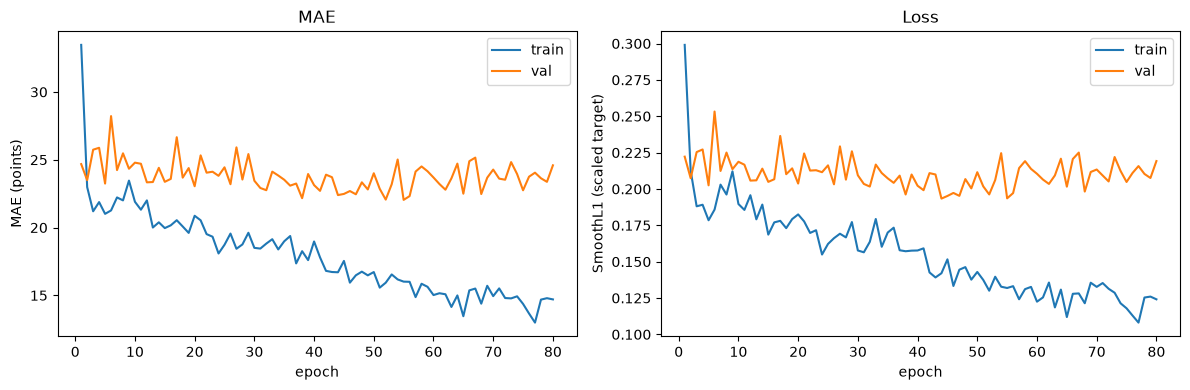

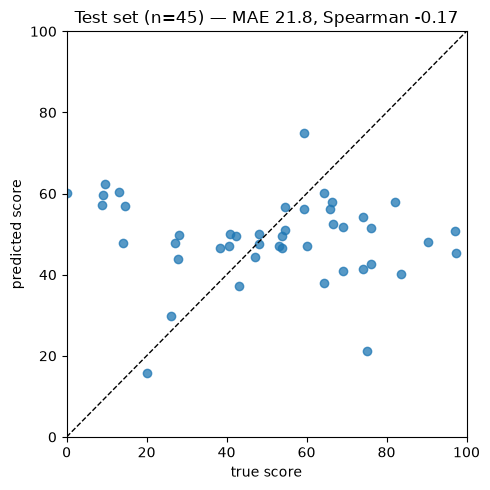

{'mae': 21.78679847717285, 'rmse': 28.256183624267578, 'pearson': -0.11147669702768326, 'spearman': -0.1720423068186741}


In [ ]:
# --- 4. Baseline diagnostics: curves + test predictions ------------------
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

history = pd.read_csv(DATA_DIR / "baseline_history.csv", sep=",")
test_metrics, test_pred, test_true = evaluate(model, test_loader)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["epoch"], history["train_mae"], label="train")
axes[0].plot(history["epoch"], history["val_mae"], label="val")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("MAE (points)")
axes[0].set_title("MAE")
axes[0].legend()

axes[1].plot(history["epoch"], history["train_loss"], label="train")
axes[1].plot(history["epoch"], history["val_loss"], label="val")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("SmoothL1 (scaled target)")
axes[1].set_title("Loss")
axes[1].legend()
fig.tight_layout()
fig.savefig(DATA_DIR / "baseline_curves.png", dpi=150)

fig2, ax = plt.subplots(figsize=(5, 5))
ax.scatter(test_true, test_pred, alpha=0.75)
ax.plot([0, 100], [0, 100], "k--", linewidth=1)
ax.set_xlabel("true score")
ax.set_ylabel("predicted score")
ax.set_title(f"Test set (n={len(test_true)}) — MAE {test_metrics['mae']:.1f}, "
             f"Spearman {test_metrics['spearman']:+.2f}")
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
fig2.tight_layout()
fig2.savefig(DATA_DIR / "baseline_test_predictions.png", dpi=150)
plt.show()
print(test_metrics)


In [ ]:
# --- 5. Pose ST-GCN-lite + CORAL ordinal head, 5-fold CV + ensemble ------
# Graph convolutions over the COCO-17 skeleton, per-frame pose normalisation,
# attention pooling, and an ordinal head over 10 score bins. CV runs on
# train+val (183 clips); the 20-clip test set is never used for training.
# Fold fitting uses the augmented pose split; early-stop/val/test are clean.
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import pearsonr, spearmanr
from torch.utils.data import ConcatDataset, DataLoader, Subset

assert all(name in globals() for name in ("train_dataset", "val_dataset", "test_dataset")), \
    "Run the dataset cell (2) first."

DATA_DIR = Path("C:/Users/franc/Downloads/AQA-7/AQA-7/Actions/ski_big_air")
CKPT_DIR = DATA_DIR / "checkpoints"
CKPT_DIR.mkdir(exist_ok=True)

SEED = 42
NUM_FOLDS = 5
NUM_BINS = 10
STGCN_EPOCHS = 120
STGCN_PATIENCE = 15
STGCN_BATCH_SIZE = 32
STGCN_LR = 1e-3
STGCN_WD = 5e-4
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

FLIP_INDEX = torch.tensor([0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13, 16, 15])

COCO_EDGES = [
    (0, 1), (0, 2), (1, 3), (2, 4),
    (0, 5), (0, 6), (5, 7), (7, 9), (6, 8), (8, 10),
    (5, 6), (5, 11), (6, 12),
    (11, 13), (13, 15), (12, 14), (14, 16),
    (11, 12),
]


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def flip_poses(x):
    """Mirror x and swap left/right joints. x: (batch, time, 17, 3)."""
    x = x.clone()
    x[..., 0] = 1.0 - x[..., 0]
    return x[:, :, FLIP_INDEX.to(x.device), :]


def build_adjacency(num_joints=17, edges=COCO_EDGES):
    """Symmetric skeleton adjacency with self-loops, D^-1/2 (A + I) D^-1/2."""
    a = np.eye(num_joints, dtype=np.float32)
    for i, j in edges:
        a[i, j] = a[j, i] = 1.0
    d_inv_sqrt = np.diag(1.0 / np.sqrt(a.sum(axis=1)))
    return d_inv_sqrt @ a @ d_inv_sqrt


def pose_features(x):
    """Per-frame translation/scale normalisation + confidence + velocities."""
    conf = x[..., 2:3]
    valid = (conf > 0.1).float()
    xy = x[..., :2] * valid
    count = valid.sum(dim=2, keepdim=True).clamp(min=1.0)
    mean = (xy * valid).sum(dim=2, keepdim=True) / count
    dev = (xy - mean) * valid
    std = ((dev ** 2).sum(dim=2, keepdim=True) / count).sqrt().clamp(min=1e-3)
    xy_n = dev / std
    velocity = torch.zeros_like(xy_n)
    velocity[:, 1:] = xy_n[:, 1:] - xy_n[:, :-1]
    return torch.cat([xy_n, conf, velocity], dim=-1)   # (B, T, 17, 5)


class STGCNBlock(nn.Module):
    def __init__(self, in_ch, out_ch, adjacency, temporal_kernel=5, dropout=0.2):
        super().__init__()
        self.register_buffer("A", torch.as_tensor(adjacency, dtype=torch.float32))
        self.gcn = nn.Conv2d(in_ch, out_ch, kernel_size=1)
        self.gcn_bn = nn.BatchNorm2d(out_ch)
        self.tcn = nn.Sequential(
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=(temporal_kernel, 1),
                      padding=(temporal_kernel // 2, 0)),
            nn.BatchNorm2d(out_ch),
            nn.Dropout(dropout),
        )
        self.residual = (nn.Identity() if in_ch == out_ch else
                         nn.Sequential(nn.Conv2d(in_ch, out_ch, 1), nn.BatchNorm2d(out_ch)))

    def forward(self, x):
        residual = self.residual(x)
        x = torch.einsum("vw,bctw->bctv", self.A, x)
        x = F.relu(self.gcn_bn(self.gcn(x)))
        x = self.tcn(x)
        return F.relu(x + residual)


class AttentionPool(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.score = nn.Linear(channels, 1)

    def forward(self, x):
        h = x.mean(dim=-1).transpose(1, 2)          # (B, T, C)
        weights = torch.softmax(self.score(h), dim=1)
        return (weights * h).sum(dim=1)


class PoseSTGCN(nn.Module):
    def __init__(self, in_channels=5, channels=(32, 32, 64), num_bins=NUM_BINS,
                 temporal_kernel=5, dropout=0.3):
        super().__init__()
        self.input_bn = nn.BatchNorm2d(in_channels)
        adjacency = build_adjacency()
        self.blocks = nn.ModuleList()
        previous = in_channels
        for width in channels:
            self.blocks.append(STGCNBlock(previous, width, adjacency, temporal_kernel, dropout))
            previous = width
        self.pool = AttentionPool(previous)
        self.head = nn.Sequential(
            nn.LayerNorm(previous), nn.Dropout(dropout), nn.Linear(previous, num_bins - 1)
        )

    def forward(self, x):
        x = pose_features(x).permute(0, 3, 1, 2)    # (B, 5, T, V)
        x = self.input_bn(x)
        for block in self.blocks:
            x = block(x)
        return self.head(self.pool(x))


def coral_loss(logits, bins, num_bins=NUM_BINS):
    """Coral / ordinal binary cross-entropy over the K-1 cumulative thresholds."""
    levels = torch.arange(num_bins - 1, device=logits.device)
    targets = (bins.unsqueeze(1) >= levels.unsqueeze(0)).float()
    return F.binary_cross_entropy_with_logits(logits, targets)


def coral_predict(logits, num_bins=NUM_BINS):
    """Expected bin = sum_k P(y >= k); mapped linearly to the 0-100 score range."""
    return torch.sigmoid(logits).sum(dim=1) * (100.0 / (num_bins - 1))


def regression_metrics(y_true, y_pred):
    if np.std(y_pred) == 0 or np.std(y_true) == 0:
        pearson = spearman = float("nan")
    else:
        pearson = float(pearsonr(y_true, y_pred)[0])
        spearman = float(spearmanr(y_true, y_pred)[0])
    return {
        "mae": float(np.mean(np.abs(y_true - y_pred))),
        "rmse": float(np.sqrt(np.mean((y_true - y_pred) ** 2))),
        "pearson": pearson,
        "spearman": spearman,
    }


@torch.no_grad()
def predict_loader(model, loader):
    model.eval()
    predictions, targets = [], []
    for x, y in loader:
        predictions.append(coral_predict(model(x.to(DEVICE)), NUM_BINS).cpu().numpy())
        targets.append(y.numpy())
    return np.concatenate(predictions), np.concatenate(targets)


def stratified_fold_ids(targets, n_splits, seed):
    """Balanced target bins, then round-robin assignment to folds."""
    bins = pd.qcut(pd.Series(targets).rank(method="first"), n_splits, labels=False).to_numpy()
    rng = np.random.default_rng(seed)
    fold_ids = np.empty(len(targets), dtype=int)
    for b in range(n_splits):
        index = np.flatnonzero(bins == b)
        rng.shuffle(index)
        fold_ids[index] = np.arange(len(index)) % n_splits
    return fold_ids


def train_fold(fit_loader, es_loader, seed):
    set_seed(seed)
    model = PoseSTGCN().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=STGCN_LR,
                                  weight_decay=STGCN_WD)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=STGCN_EPOCHS)
    best_mae, best_epoch, wait, best_state = float("inf"), 0, 0, None

    for epoch in range(1, STGCN_EPOCHS + 1):
        model.train()
        for x, y in fit_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            # Augmentation is applied by PoseAugmenter in the fit dataset.
            bin_width = 100.0 / NUM_BINS
            bins = torch.div(y, bin_width, rounding_mode="floor").long().clamp_(0, NUM_BINS - 1)
            loss = coral_loss(model(x), bins)
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            optimizer.step()
        scheduler.step()

        es_pred, es_true = predict_loader(model, es_loader)
        es_mae = float(np.mean(np.abs(es_pred - es_true)))
        if es_mae < best_mae - 1e-3:
            best_mae, best_epoch, wait = es_mae, epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= STGCN_PATIENCE:
                break

    model.load_state_dict(best_state)
    return model, best_mae, best_epoch


pool_df = pd.concat([train_dataset.data, val_dataset.data], ignore_index=True)
pool_targets = pool_df["target"].to_numpy(dtype=float)
cv_pool = PoseSequenceDataset(pool_df, augment=False)
cv_pool_aug = PoseSequenceDataset(pool_df, augment=True,
                                  augmenter=train_augmenter)
assert len(cv_pool) == len(cv_pool_aug) == len(pool_df)
print(f"CV pool: {len(cv_pool)} clips (clean eval + augmented fit) | "
      f"test holdout: {len(test_dataset)} clips")
print(f"model: {sum(p.numel() for p in PoseSTGCN().parameters()):,} parameters | device: {DEVICE}")

fold_ids = stratified_fold_ids(pool_targets, NUM_FOLDS, SEED)
oof_pred = np.full(len(pool_targets), np.nan)
oof_mean = np.full(len(pool_targets), np.nan)
fold_models, fold_rows = [], []

for fold in range(NUM_FOLDS):
    outer = np.flatnonzero(fold_ids == fold)
    train_idx = np.flatnonzero(fold_ids != fold)
    inner = stratified_fold_ids(pool_targets[train_idx], 8, seed=100 + fold)
    fit_idx, es_idx = train_idx[inner != 0], train_idx[inner == 0]

    fit_loader = DataLoader(Subset(cv_pool_aug, fit_idx),
                            batch_size=STGCN_BATCH_SIZE, shuffle=True,
                            num_workers=0)
    es_loader = DataLoader(Subset(cv_pool, es_idx), batch_size=STGCN_BATCH_SIZE,
                           shuffle=False, num_workers=0)
    outer_loader = DataLoader(Subset(cv_pool, outer), batch_size=STGCN_BATCH_SIZE,
                              shuffle=False, num_workers=0)

    start = time.time()
    model, es_mae, es_epoch = train_fold(fit_loader, es_loader, seed=SEED + fold)
    pred, true = predict_loader(model, outer_loader)
    oof_pred[outer] = pred
    oof_mean[outer] = pool_targets[fit_idx].mean()
    fold_models.append(model)
    torch.save(model.state_dict(), CKPT_DIR / f"stgcn_fold{fold}.pt")

    row = {
        "fold": fold, "train": len(fit_idx), "early_stop": len(es_idx),
        "outer": len(outer), "es_mae": es_mae, "es_epoch": es_epoch,
        "fold_mae": float(np.mean(np.abs(pred - true))),
        "mean_mae": float(np.mean(np.abs(oof_mean[outer] - true))),
        "seconds": round(time.time() - start, 1),
    }
    fold_rows.append(row)
    print(f"fold {fold}: train {len(fit_idx):3d} | es MAE {es_mae:5.2f} @ ep {es_epoch:3d} "
          f"| outer MAE {row['fold_mae']:5.2f} (mean {row['mean_mae']:5.2f}) "
          f"| {row['seconds']:.0f}s")

assert np.isfinite(oof_pred).all()
oof_df = pool_df[["filename", "target"]].copy()
oof_df["oof_pred"] = oof_pred
oof_df["mean_pred"] = oof_mean
oof_df["fold"] = fold_ids
oof_df.to_csv(DATA_DIR / "stgcn_oof.csv", sep=",", index=False)

fold_df = pd.DataFrame(fold_rows)
fold_df.to_csv(DATA_DIR / "stgcn_cv_folds.csv", sep=",", index=False)

# --- Ensemble the five fold models on the untouched test set -------------
test_loader = DataLoader(test_dataset, batch_size=STGCN_BATCH_SIZE, shuffle=False, num_workers=0)
fold_test_preds = np.stack([predict_loader(model, test_loader)[0] for model in fold_models])
test_targets = test_dataset.data["target"].to_numpy(dtype=float)
test_pred = fold_test_preds.mean(axis=0)
train_mean = float(train_dataset.data["target"].mean())

test_df = pd.DataFrame({
    "filename": test_dataset.data["filename"].astype(str).to_numpy(),
    "target": test_targets,
    "pred_mean": test_pred,
    "mean_baseline": train_mean,
})
for fold in range(NUM_FOLDS):
    test_df[f"pred_fold{fold}"] = fold_test_preds[fold]
test_df.to_csv(DATA_DIR / "stgcn_test_predictions.csv", sep=",", index=False)

oof_metrics = regression_metrics(pool_targets, oof_pred)
oof_mean_metrics = regression_metrics(pool_targets, oof_mean)
test_metrics = regression_metrics(test_targets, test_pred)
test_mean_metrics = regression_metrics(test_targets, np.full_like(test_targets, train_mean))

summary = pd.DataFrame([
    {"scope": "OOF (5-fold)", **oof_metrics},
    {"scope": "OOF (predict fold mean)", **oof_mean_metrics},
    {"scope": "TEST (5-model ensemble)", **test_metrics},
    {"scope": "TEST (predict train mean)", **test_mean_metrics},
])
summary.to_csv(DATA_DIR / "stgcn_summary.csv", sep=",", index=False)

print("\n5-fold OOF (183 clips):")
print(f"  ST-GCN  MAE {oof_metrics['mae']:5.2f} | RMSE {oof_metrics['rmse']:5.2f} "
      f"| Pearson {oof_metrics['pearson']:+.2f} | Spearman {oof_metrics['spearman']:+.2f}")
print(f"  mean    MAE {oof_mean_metrics['mae']:5.2f} | RMSE {oof_mean_metrics['rmse']:5.2f}")
print("\nTest ensemble (20 clips):")
print(f"  ST-GCN  MAE {test_metrics['mae']:5.2f} | RMSE {test_metrics['rmse']:5.2f} "
      f"| Pearson {test_metrics['pearson']:+.2f} | Spearman {test_metrics['spearman']:+.2f}")
print(f"  mean    MAE {test_mean_metrics['mae']:5.2f} | RMSE {test_mean_metrics['rmse']:5.2f}")
print(f"\nper-fold test MAE range: "
      f"{np.min(np.abs(fold_test_preds - test_targets).mean(axis=1)):.2f}"
      f"-{np.max(np.abs(fold_test_preds - test_targets).mean(axis=1)):.2f}")


CV pool: 189 clips (clean eval + augmented fit) | test holdout: 45 clips
model: 38,260 parameters | device: cpu


KeyboardInterrupt: 

In [ ]:
# --- 6. ST-GCN CV diagnostics -------------------------------------------
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.stats import pearsonr, spearmanr

DATA_DIR = Path("C:/Users/franc/Downloads/AQA-7/AQA-7/Actions/ski_big_air")
oof_df = pd.read_csv(DATA_DIR / "stgcn_oof.csv", sep=",")
fold_df = pd.read_csv(DATA_DIR / "stgcn_cv_folds.csv", sep=",")
test_df = pd.read_csv(DATA_DIR / "stgcn_test_predictions.csv", sep=",")


def metrics(y_true, y_pred):
    return {
        "mae": float(np.mean(np.abs(y_true - y_pred))),
        "rmse": float(np.sqrt(np.mean((y_true - y_pred) ** 2))),
        "pearson": float(pearsonr(y_true, y_pred)[0]) if np.std(y_pred) else float("nan"),
        "spearman": float(spearmanr(y_true, y_pred)[0]) if np.std(y_pred) else float("nan"),
    }


oof_metrics = metrics(oof_df["target"], oof_df["oof_pred"])
oof_mean_metrics = metrics(oof_df["target"], oof_df["mean_pred"])
test_metrics = metrics(test_df["target"], test_df["pred_mean"])
test_mean_metrics = metrics(test_df["target"], test_df["mean_baseline"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

for fold, group in oof_df.groupby("fold"):
    axes[0].scatter(group["target"], group["oof_pred"], alpha=0.7, label=f"fold {fold}")
axes[0].plot([0, 100], [0, 100], "k--", linewidth=1)
axes[0].set_xlim(0, 100)
axes[0].set_ylim(0, 100)
axes[0].set_xlabel("true score")
axes[0].set_ylabel("out-of-fold prediction")
axes[0].set_title(f"5-fold OOF (n={len(oof_df)}) — MAE {oof_metrics['mae']:.1f}, "
                  f"Spearman {oof_metrics['spearman']:+.2f}")
axes[0].legend(fontsize=8)

x = fold_df["fold"].to_numpy()
axes[1].bar(x - 0.2, fold_df["fold_mae"], width=0.4, label="ST-GCN")
axes[1].bar(x + 0.2, fold_df["mean_mae"], width=0.4, label="predict fold mean")
axes[1].axhline(oof_metrics["mae"], color="C0", linestyle=":", linewidth=1,
                label=f"OOF MAE {oof_metrics['mae']:.1f}")
axes[1].set_xticks(x)
axes[1].set_xlabel("fold")
axes[1].set_ylabel("MAE (points)")
axes[1].set_title("Per-fold error vs mean baseline")
axes[1].legend(fontsize=8)

fold_cols = [c for c in test_df.columns if c.startswith("pred_fold")]
for col in fold_cols:
    axes[2].scatter(test_df["target"], test_df[col], alpha=0.45, s=18,
                    label="single fold" if col == fold_cols[0] else None)
axes[2].scatter(test_df["target"], test_df["pred_mean"], alpha=0.9,
                label="ensemble", color="C3")
axes[2].plot([0, 100], [0, 100], "k--", linewidth=1)
axes[2].set_xlim(0, 100)
axes[2].set_ylim(0, 100)
axes[2].set_xlabel("true score")
axes[2].set_ylabel("predicted score")
axes[2].set_title(f"Test ensemble (n={len(test_df)}) — MAE {test_metrics['mae']:.1f}, "
                  f"Spearman {test_metrics['spearman']:+.2f}")
axes[2].legend(fontsize=8)

fig.tight_layout()
fig.savefig(DATA_DIR / "stgcn_diagnostics.png", dpi=150)
plt.show()

print(pd.DataFrame([
    {"scope": "OOF (5-fold)", **oof_metrics},
    {"scope": "OOF (predict fold mean)", **oof_mean_metrics},
    {"scope": "TEST (5-model ensemble)", **test_metrics},
    {"scope": "TEST (predict train mean)", **test_mean_metrics},
]).round(3).to_string(index=False))
